In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.stats import weightstats
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.tsa.stattools import adfuller
import statsmodels.api as sm
from scipy.stats import ttest_ind, f_oneway
from statsmodels.formula.api import ols
from scipy.stats import zscore
import warnings
warnings.filterwarnings("ignore")

## RQ1: What are the high-risk (high propagation costs) packages created in the source and build stages when considering OSS supply-chain risk through models of network propagation?


## Build Phase Analysis

In [ ]:
ind_df = pd.read_csv('/content/indegree.csv',header=0)
# publish_df = pd.read_csv('/Users/sahithikasim/Downloads/thesis/publish_sections.csv',header=0)
pop_df = pd.read_csv('/content/popularity.csv',header=0)
# path_df = pd.read_csv('/Users/sahithikasim/Downloads/thesis/longest_paths_with_packages.csv', header=0)
path_df = pd.read_csv('/content/path_length.csv', header=0)
attack_df = pd.read_csv('/content/attack_radius.csv', header=0)
# bet_df = pd.read_csv('/Users/sahithikasim/Downloads/thesis/betweenness_centrality_build.csv', header=0)
core_df = pd.read_csv('/content/k_core_index.csv', header=0)
vuln_df = pd.read_csv('/content/past_vulnerable_packages.csv', header=0)

In [ ]:
print(ind_df.shape)
print(path_df.shape)
# print(bet_df.shape)
print(core_df.shape)
print(attack_df.shape)
print(pop_df.shape)
print(vuln_df.shape)

(347475, 2)
(347475, 2)
(347475, 2)
(347475, 2)
(196176, 8)
(3539, 1)


In [ ]:
print(ind_df.head())
print(path_df.head())
# print(bet_df.head())
print(core_df.head())
print(attack_df.head())


          Node  In-Degree
0   base-files      37772
1  base-passwd      37772
2         bash      37772
3     binutils      37772
4     bsdutils      37772
                  Node  Path Length
0      twig-extensions          937
1              symfony          936
2              shaarli          936
3  php-doctrine-bundle          935
4           phpmyadmin          935
              Node  K-Core Index
0         liggghts           575
1  libliggghts-dev             1
2     libliggghts3             1
3     liggghts-doc             1
4          adduser           576
            Node  Attack Radius
0        adduser             12
1  autotools-dev             12
2     base-files             12
3       binutils             12
4   bsdmainutils             12


In [ ]:
print(pop_df.head())
print(vuln_df.head())

   rank     name    inst    vote   old  recent  no-files  \
0     1  adduser  234785  211590  4924   18233        38   
1     2  libacl1  234785  214251  2906   17588        40   
2     3      tar  234785  213292  3464   17986        43   
3     4   passwd  234784  213145  3410   18191        38   
4     5  debconf  234782  214125  2631   17996        30   

                   maintainer  
0   Debian Adduser Developers  
1               Guillem Jover  
2                Janos Lenart  
3  Shadow Package Maintainers  
4          Debconf Developers  
      Packages
0  389-ds-base
1         7zip
2        9base
3         a2ps
4      abcm2ps


### Data Cleaning

In [ ]:
# Initialize combined_df with the index of attack_df and fill with 0s
combined_df = attack_df.copy()

# Merge each dataframe into combined_df
combined_df = combined_df.merge(ind_df, on='Node', how='left').fillna(0)
combined_df = combined_df.merge(path_df, on='Node', how='left').fillna(0)
# combined_df = combined_df.merge(bet_df, on='Node', how='left').fillna(0)
combined_df = combined_df.merge(core_df, on='Node', how='left').fillna(0)

print(combined_df.shape)
print(combined_df.head())

(347475, 5)
            Node  Attack Radius  In-Degree  Path Length  K-Core Index
0        adduser             12       8336          875           576
1  autotools-dev             12      37719          871           576
2     base-files             12      37772          871           576
3       binutils             12      37772          871           576
4   bsdmainutils             12      30158          871           576


In [ ]:
# Clean the DataFrame
combined_df['Node'] = combined_df['Node'].str.replace('"', '').str.strip()

### Descriptive Analysis of Build Data

In [ ]:
combined_df.describe()

,Attack Radius,In-Degree,Path Length,K-Core Index
count,347475.000000,347475.000000,347475.000000,347475.000000
mean,1.249747,37.471309,95.045085,38.490240
std,3.583149,862.017968,272.163369,108.261723
min,0.000000,0.000000,0.000000,1.000000
25%,0.000000,1.000000,0.000000,1.000000
50%,0.000000,1.000000,0.000000,1.000000
75%,0.000000,1.000000,0.000000,2.000000
max,12.000000,37772.000000,937.000000,576.000000


In [ ]:
# Select columns with numerical data
numerical_columns = combined_df.select_dtypes(include=['int', 'float']).columns

# Calculate median for numerical columns
numerical_medians = combined_df[numerical_columns].median()

# Display the median values for numerical columns
print("Median values for numerical columns:")
print(numerical_medians)


Median values for numerical columns:
Attack Radius    0.0
In-Degree        1.0
Path Length      0.0
K-Core Index     1.0
dtype: float64


### Data Visualizations

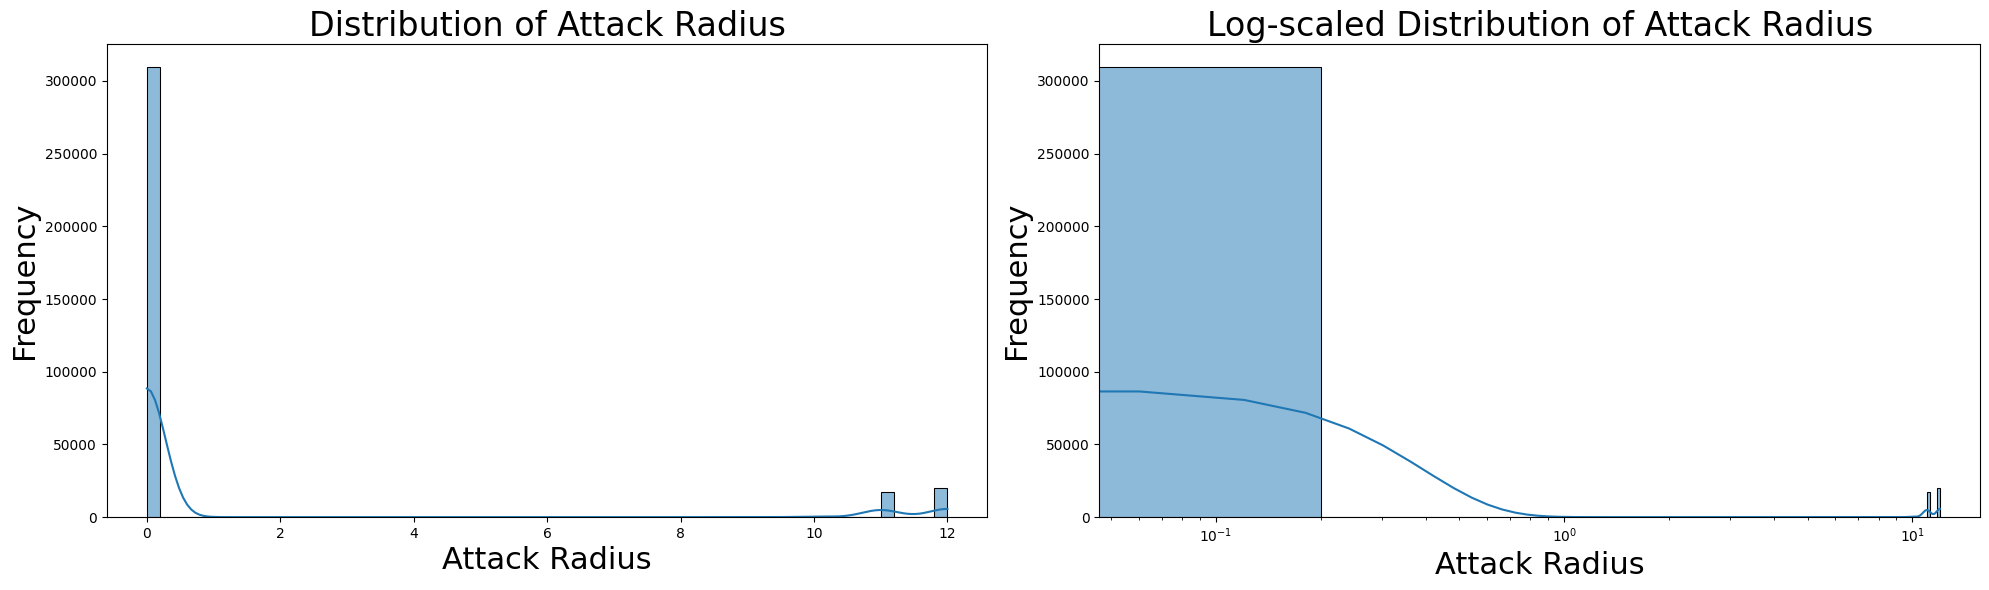

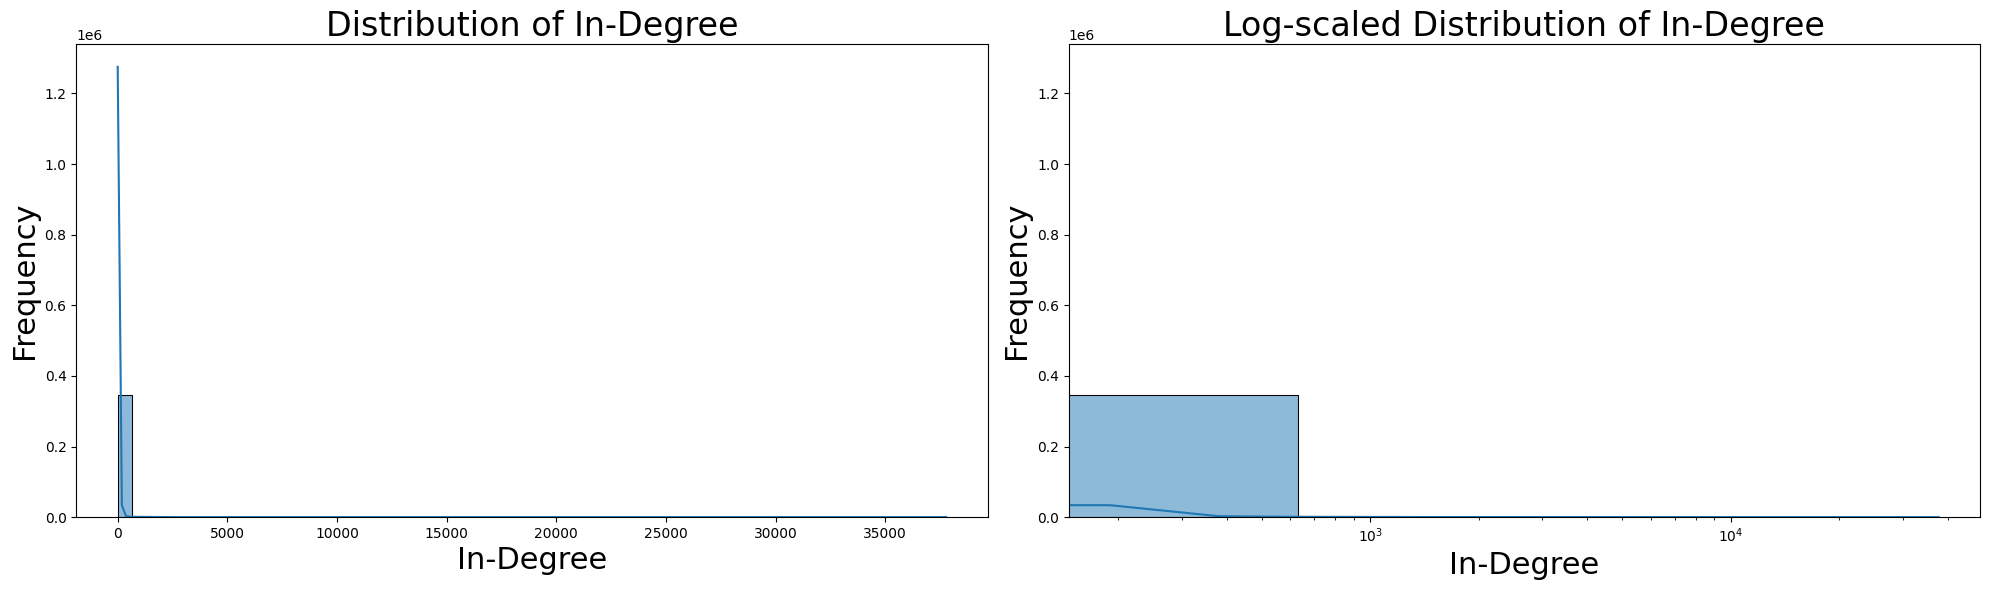

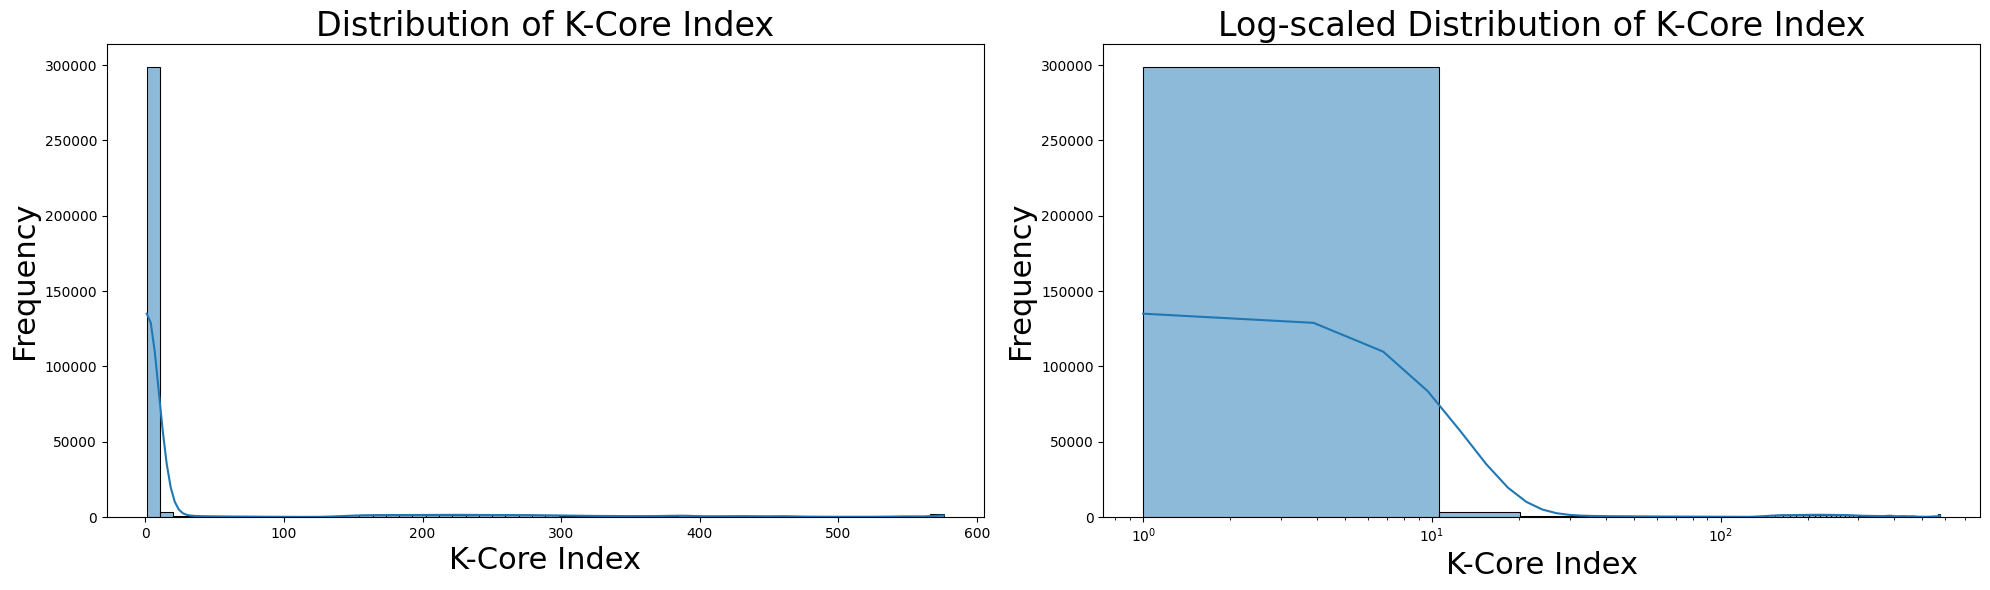

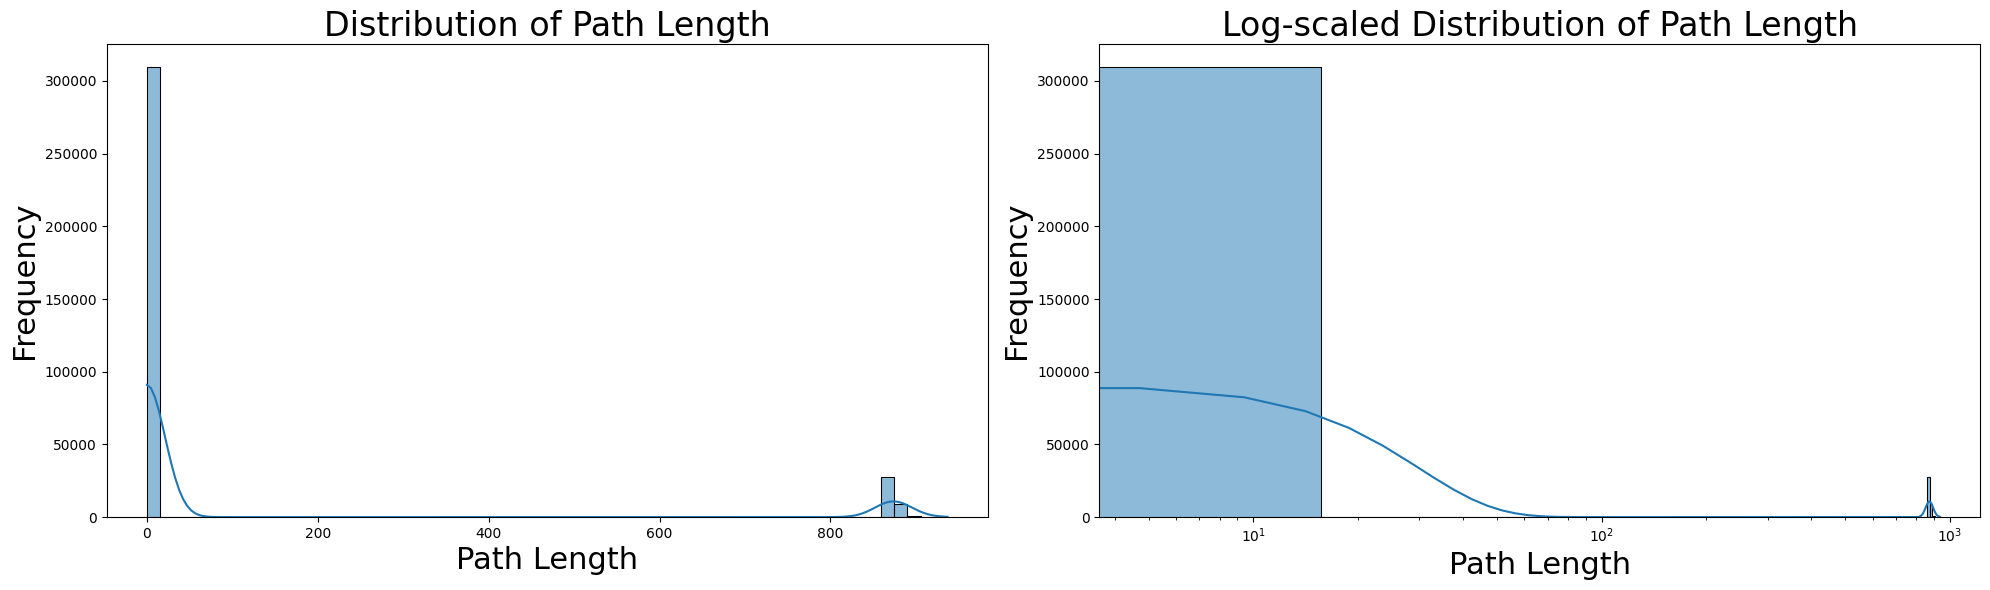

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# metrics = ['Attack Radius', 'In-Degree', 'Betweenness Centrality', 'K-Core Index', 'Path Length']
metrics = ['Attack Radius', 'In-Degree', 'K-Core Index', 'Path Length']

for metric in metrics:
    fig, axes = plt.subplots(1, 2, figsize=(20, 6))

    # Histogram
    sns.histplot(combined_df[metric], kde=True, bins=60, ax=axes[0])
    axes[0].set_title(f'Distribution of {metric}', fontsize=24)
    axes[0].set_xlabel(metric, fontsize=22)
    axes[0].set_ylabel('Frequency', fontsize=22)

    # Log-scaled distribution plot
    sns.histplot(combined_df[metric], kde=True, bins=60, ax=axes[1])
    axes[1].set_title(f'Log-scaled Distribution of {metric}', fontsize=24)
    axes[1].set_xlabel(metric, fontsize=22)
    axes[1].set_ylabel('Frequency', fontsize=22)
    axes[1].set_xscale('log')

    plt.tight_layout()
    plt.show()


Top 10 Unique Values: [567 568 569 570 571 572 573 574 575 576]
Middle 10 Unique Values: [284 285 286 287 288 289 290 291 292 293]


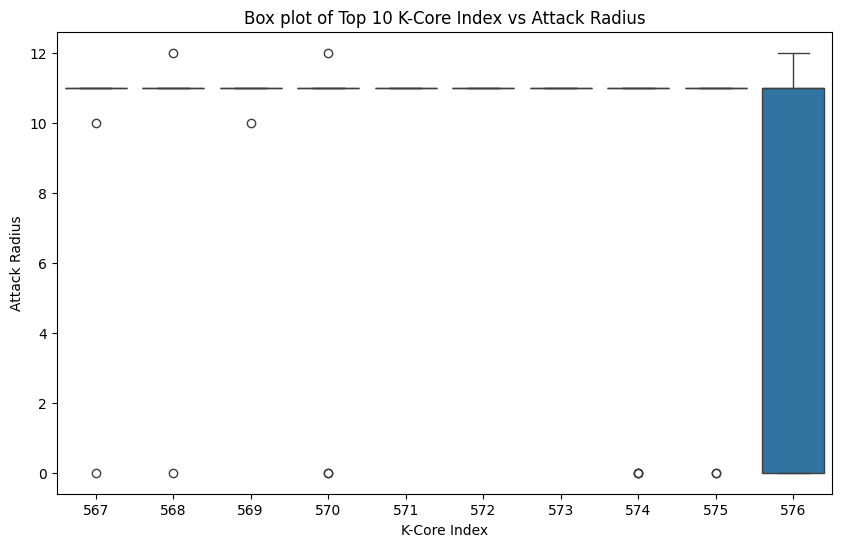

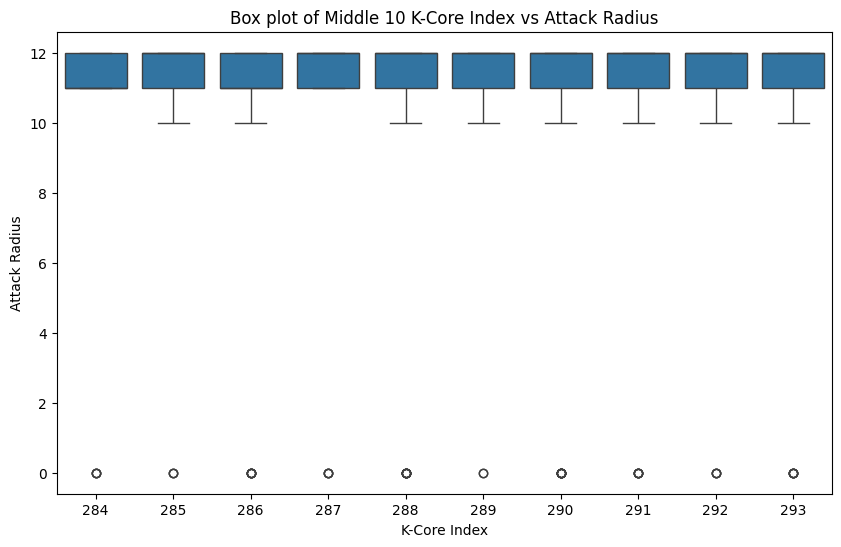

In [ ]:
# Sort the data based on 'Core Value'
sorted_df = combined_df.sort_values('K-Core Index')

# Get unique values from the 'Core Value' column
unique_core_values = sorted_df['K-Core Index'].unique()

# Extract the top 10 unique values
top_values = unique_core_values[-10:]

# Extract the middle 10 unique values
middle_index = len(unique_core_values) // 2
middle_values = unique_core_values[middle_index - 5 : middle_index + 5]

print("Top 10 Unique Values:", top_values)
print("Middle 10 Unique Values:", middle_values)

# Filter the DataFrame for the top and middle values
top_df = sorted_df[sorted_df['K-Core Index'].isin(top_values)]
middle_df = sorted_df[sorted_df['K-Core Index'].isin(middle_values)]

# Create box plots for top values
plt.figure(figsize=(10, 6))
sns.boxplot(x='K-Core Index', y='Attack Radius', data=top_df)
plt.title('Box plot of Top 10 K-Core Index vs Attack Radius')
plt.show()

# Create box plots for middle values
plt.figure(figsize=(10, 6))
sns.boxplot(x='K-Core Index', y='Attack Radius', data=middle_df)
plt.title('Box plot of Middle 10 K-Core Index vs Attack Radius')
plt.show()


### Proposition: Packages with a high propagation costs are more likely to be vulnerable.

### Outlier Analysis

#### Top 5%

In [ ]:
# Helper function to detect outliers
def detect_outliers(df, column):
    Q1 = df[column].quantile(0)
    Q3 = df[column].quantile(0.95)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = df[(df[column] < lower_bound) | (df[column] > upper_bound)]
    return outliers

# Store outliers in a DataFrame
outliers_dict = {metric: [] for metric in metrics}

# Visualizations and Outlier Analysis
for metric in metrics:
    outliers = detect_outliers(combined_df, metric)
    outliers_dict[metric].extend(outliers['Node'].values)

# Convert outliers_dict to DataFrame
outliers_df = pd.DataFrame([(node, metric) for metric, nodes in outliers_dict.items() for node in nodes], columns=['Node', 'Metric'])

# Combine metrics for each node
outliers_combined = outliers_df.groupby('Node')['Metric'].apply(lambda x: ', '.join(x)).reset_index()

# Identify outliers that match vulnerability nodes
vulnerability_nodes = set(vuln_df['Packages'])
common_outliers_count = {metric: len(set(nodes) & vulnerability_nodes) for metric, nodes in outliers_dict.items()}

# Print count of outliers that match vulnerability nodes for each metric
for metric, count in common_outliers_count.items():
    print(f"Number of outliers in {metric} that match vulnerability nodes: {count}")


Number of outliers in Attack Radius that match vulnerability nodes: 0
Number of outliers in In-Degree that match vulnerability nodes: 390
Number of outliers in K-Core Index that match vulnerability nodes: 0
Number of outliers in Path Length that match vulnerability nodes: 0


#### Top 10%

In [ ]:
# Helper function to detect outliers
def detect_outliers(df, column):
    Q1 = df[column].quantile(0)
    Q3 = df[column].quantile(0.90)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = df[(df[column] < lower_bound) | (df[column] > upper_bound)]
    return outliers

# Store outliers in a DataFrame
outliers_dict = {metric: [] for metric in metrics}

# Visualizations and Outlier Analysis
for metric in metrics:
    outliers = detect_outliers(combined_df, metric)
    outliers_dict[metric].extend(outliers['Node'].values)

# Convert outliers_dict to DataFrame
outliers_df = pd.DataFrame([(node, metric) for metric, nodes in outliers_dict.items() for node in nodes], columns=['Node', 'Metric'])

# Combine metrics for each node
outliers_combined = outliers_df.groupby('Node')['Metric'].apply(lambda x: ', '.join(x)).reset_index()

# Identify outliers that match vulnerability nodes
vulnerability_nodes = set(vuln_df['Packages'])
common_outliers_count = {metric: len(set(nodes) & vulnerability_nodes) for metric, nodes in outliers_dict.items()}

# Print count of outliers that match vulnerability nodes for each metric
for metric, count in common_outliers_count.items():
    print(f"Number of outliers in {metric} that match vulnerability nodes: {count}")


Number of outliers in Attack Radius that match vulnerability nodes: 0
Number of outliers in In-Degree that match vulnerability nodes: 582
Number of outliers in K-Core Index that match vulnerability nodes: 885
Number of outliers in Path Length that match vulnerability nodes: 0


#### Top and bottom 5%

In [ ]:
# Helper function to detect outliers
def detect_outliers(df, column):
    Q1 = df[column].quantile(0.05)
    Q3 = df[column].quantile(0.95)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = df[(df[column] < lower_bound) | (df[column] > upper_bound)]
    return outliers

# Store outliers in a DataFrame
outliers_dict = {metric: [] for metric in metrics}

# Visualizations and Outlier Analysis
for metric in metrics:
    outliers = detect_outliers(combined_df, metric)
    outliers_dict[metric].extend(outliers['Node'].values)

# Convert outliers_dict to DataFrame
outliers_df = pd.DataFrame([(node, metric) for metric, nodes in outliers_dict.items() for node in nodes], columns=['Node', 'Metric'])

# Combine metrics for each node
outliers_combined = outliers_df.groupby('Node')['Metric'].apply(lambda x: ', '.join(x)).reset_index()

# Identify outliers that match vulnerability nodes
vulnerability_nodes = set(vuln_df['Packages'])
common_outliers_count = {metric: len(set(nodes) & vulnerability_nodes) for metric, nodes in outliers_dict.items()}

# Print count of outliers that match vulnerability nodes for each metric
for metric, count in common_outliers_count.items():
    print(f"Number of outliers in {metric} that match vulnerability nodes: {count}")


Number of outliers in Attack Radius that match vulnerability nodes: 0
Number of outliers in In-Degree that match vulnerability nodes: 401
Number of outliers in K-Core Index that match vulnerability nodes: 0
Number of outliers in Path Length that match vulnerability nodes: 0


#### Top and bottom 10%

In [ ]:
# Helper function to detect outliers
def detect_outliers(df, column):
    Q1 = df[column].quantile(0.1)
    Q3 = df[column].quantile(0.9)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = df[(df[column] < lower_bound) | (df[column] > upper_bound)]
    return outliers

# Store outliers in a DataFrame
outliers_dict = {metric: [] for metric in metrics}

# Visualizations and Outlier Analysis
for metric in metrics:
    outliers = detect_outliers(combined_df, metric)
    outliers_dict[metric].extend(outliers['Node'].values)

# Convert outliers_dict to DataFrame
outliers_df = pd.DataFrame([(node, metric) for metric, nodes in outliers_dict.items() for node in nodes], columns=['Node', 'Metric'])

# Combine metrics for each node
outliers_combined = outliers_df.groupby('Node')['Metric'].apply(lambda x: ', '.join(x)).reset_index()

# Identify outliers that match vulnerability nodes
vulnerability_nodes = set(vuln_df['Packages'])
common_outliers_count = {metric: len(set(nodes) & vulnerability_nodes) for metric, nodes in outliers_dict.items()}

# Print count of outliers that match vulnerability nodes for each metric
for metric, count in common_outliers_count.items():
    print(f"Number of outliers in {metric} that match vulnerability nodes: {count}")


Number of outliers in Attack Radius that match vulnerability nodes: 0
Number of outliers in In-Degree that match vulnerability nodes: 704
Number of outliers in K-Core Index that match vulnerability nodes: 885
Number of outliers in Path Length that match vulnerability nodes: 0


### Top and Bottom 20%

In [ ]:
# Helper function to detect outliers
def detect_outliers(df, column):
    Q1 = df[column].quantile(0.2)
    Q3 = df[column].quantile(0.8)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = df[(df[column] < lower_bound) | (df[column] > upper_bound)]
    return outliers

# Store outliers in a DataFrame
outliers_dict = {metric: [] for metric in metrics}

# Visualizations and Outlier Analysis
for metric in metrics:
    outliers = detect_outliers(combined_df, metric)
    outliers_dict[metric].extend(outliers['Node'].values)

# Convert outliers_dict to DataFrame
outliers_df = pd.DataFrame([(node, metric) for metric, nodes in outliers_dict.items() for node in nodes], columns=['Node', 'Metric'])

# Combine metrics for each node
outliers_combined = outliers_df.groupby('Node')['Metric'].apply(lambda x: ', '.join(x)).reset_index()

# Identify outliers that match vulnerability nodes
vulnerability_nodes = set(vuln_df['Packages'])
common_outliers_count = {metric: len(set(nodes) & vulnerability_nodes) for metric, nodes in outliers_dict.items()}

# Print count of outliers that match vulnerability nodes for each metric
for metric, count in common_outliers_count.items():
    print(f"Number of outliers in {metric} that match vulnerability nodes: {count}")


Number of outliers in Attack Radius that match vulnerability nodes: 3466
Number of outliers in In-Degree that match vulnerability nodes: 2189
Number of outliers in K-Core Index that match vulnerability nodes: 3467
Number of outliers in Path Length that match vulnerability nodes: 3466


#### Top and bottom 15%

In [ ]:
# Helper function to detect outliers
def detect_outliers(df, column):
    Q1 = df[column].quantile(0.15)
    Q3 = df[column].quantile(0.85)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = df[(df[column] < lower_bound) | (df[column] > upper_bound)]
    return outliers

# Store outliers in a DataFrame
outliers_dict = {metric: [] for metric in metrics}

# Visualizations and Outlier Analysis
for metric in metrics:
    outliers = detect_outliers(combined_df, metric)
    outliers_dict[metric].extend(outliers['Node'].values)

# Convert outliers_dict to DataFrame
outliers_df = pd.DataFrame([(node, metric) for metric, nodes in outliers_dict.items() for node in nodes], columns=['Node', 'Metric'])

# Combine metrics for each node
outliers_combined = outliers_df.groupby('Node')['Metric'].apply(lambda x: ', '.join(x)).reset_index()

# Identify outliers that match vulnerability nodes
vulnerability_nodes = set(vuln_df['Packages'])
common_outliers_count = {metric: len(set(nodes) & vulnerability_nodes) for metric, nodes in outliers_dict.items()}

# Print count of outliers that match vulnerability nodes for each metric
for metric, count in common_outliers_count.items():
    print(f"Number of outliers in {metric} that match vulnerability nodes: {count}")


Number of outliers in Attack Radius that match vulnerability nodes: 3466
Number of outliers in In-Degree that match vulnerability nodes: 704
Number of outliers in K-Core Index that match vulnerability nodes: 3466
Number of outliers in Path Length that match vulnerability nodes: 3466


#### Top 15%

In [ ]:
# Helper function to detect outliers
def detect_outliers(df, column):
    Q1 = df[column].quantile(0)
    Q3 = df[column].quantile(0.85)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = df[(df[column] < lower_bound) | (df[column] > upper_bound)]
    return outliers

# Store outliers in a DataFrame
outliers_dict = {metric: [] for metric in metrics}

# Visualizations and Outlier Analysis
for metric in metrics:
    outliers = detect_outliers(combined_df, metric)
    outliers_dict[metric].extend(outliers['Node'].values)

# Convert outliers_dict to DataFrame
outliers_df = pd.DataFrame([(node, metric) for metric, nodes in outliers_dict.items() for node in nodes], columns=['Node', 'Metric'])

# Combine metrics for each node
outliers_combined = outliers_df.groupby('Node')['Metric'].apply(lambda x: ', '.join(x)).reset_index()

# Identify outliers that match vulnerability nodes
vulnerability_nodes = set(vuln_df['Packages'])
common_outliers_count = {metric: len(set(nodes) & vulnerability_nodes) for metric, nodes in outliers_dict.items()}

# Print count of outliers that match vulnerability nodes for each metric
for metric, count in common_outliers_count.items():
    print(f"Number of outliers in {metric} that match vulnerability nodes: {count}")


Number of outliers in Attack Radius that match vulnerability nodes: 3466
Number of outliers in In-Degree that match vulnerability nodes: 582
Number of outliers in K-Core Index that match vulnerability nodes: 3466
Number of outliers in Path Length that match vulnerability nodes: 3466


In [ ]:
vuln_df.shape

(3539, 1)

In [ ]:
common_nodes_df = pd.merge(combined_df, vuln_df, left_on='Node', right_on='Packages', how='inner')
print(common_nodes_df.shape)

(3471, 6)


In [ ]:
common_nodes_df = pd.merge(outliers_combined, vuln_df, left_on='Node', right_on='Packages', how='inner')
print(common_nodes_df.shape)

(3466, 3)


In [ ]:
# Merge vulnerability data with source and build phase data
combined_df = combined_df.merge(vuln_df, left_on='Node', right_on='Packages', how='left', indicator=True)

combined_df['is_vulnerable'] = combined_df['_merge'] == 'both'

# Drop the '_merge' column
combined_df.drop(columns=['_merge'], inplace=True)

### Combined Outlier Analysis

In [ ]:
# Calculate combined outlier status for each node
combined = combined_df.copy()
combined['Combined_Outlier'] = 0  # Initialize as non-outlier
for metric in metrics:
    Q1 = combined[metric].quantile(0.05)
    Q3 = combined[metric].quantile(0.95)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    combined['Combined_Outlier'] |= (combined[metric] < lower_bound) | (combined[metric] > upper_bound)

# Filter nodes with outliers
outliers_combined = combined[combined['Combined_Outlier'] == 1]

# Find matches with vulnerability data
matches_with_vulnerability = combined[(combined['Combined_Outlier'] == 1) & (combined_df['is_vulnerable'] == 1)]

# Count the number of matches
num_matches = matches_with_vulnerability.shape[0]
print("Number of matches with vulnerability data:", num_matches)


Number of matches with vulnerability data: 401


In [ ]:
combined['Combined_Outlier'] = 0  # Initialize as non-outlier
for metric in metrics:
    Q1 = combined[metric].quantile(0.1)
    Q3 = combined[metric].quantile(0.9)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    combined['Combined_Outlier'] |= (combined[metric] < lower_bound) | (combined[metric] > upper_bound)

# Filter nodes with outliers
outliers_combined = combined[combined['Combined_Outlier'] == 1]

# Find matches with vulnerability data
matches_with_vulnerability = combined[(combined['Combined_Outlier'] == 1) & (combined['is_vulnerable'] == 1)]

# Count the number of matches
num_matches = matches_with_vulnerability.shape[0]
print("Number of matches with vulnerability data:", num_matches)


Number of matches with vulnerability data: 1313


In [ ]:
# Calculate combined outlier status for each node
combined = combined_df.copy()
combined['Combined_Outlier'] = 0  # Initialize as non-outlier
for metric in metrics:
    Q1 = combined[metric].quantile(0.15)
    Q3 = combined[metric].quantile(0.85)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    combined['Combined_Outlier'] |= (combined[metric] < lower_bound) | (combined[metric] > upper_bound)

# Filter nodes with outliers
outliers_combined = combined[combined['Combined_Outlier'] == 1]

# Find matches with vulnerability data
matches_with_vulnerability = combined[(combined['Combined_Outlier'] == 1) & (combined['is_vulnerable'] == 1)]

# Count the number of matches
num_matches = matches_with_vulnerability.shape[0]
print("Number of matches with vulnerability data:", num_matches)


Number of matches with vulnerability data: 3467


In [ ]:
# Calculate combined outlier status for each node
combined = combined_df.copy()
combined['Combined_Outlier'] = 0  # Initialize as non-outlier
for metric in metrics:
    Q1 = combined[metric].quantile(0)
    Q3 = combined[metric].quantile(0.85)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    combined['Combined_Outlier'] |= (combined[metric] < lower_bound) | (combined[metric] > upper_bound)

# Filter nodes with outliers
outliers_combined = combined[combined['Combined_Outlier'] == 1]

# Find matches with vulnerability data
matches_with_vulnerability = combined[(combined['Combined_Outlier'] == 1) & (combined['is_vulnerable'] == 1)]

# Count the number of matches
num_matches = matches_with_vulnerability.shape[0]
print("Number of matches with vulnerability data:", num_matches)


Number of matches with vulnerability data: 3466


### Clustering

In [ ]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# Combine metrics into a single dataframe
combined_metrics = combined[metrics]

# Standardize data
scaler = StandardScaler()
scaled_data = scaler.fit_transform(combined_metrics)

# Cluster analysis
kmeans = KMeans(n_clusters=1000, random_state=42)
combined['Cluster'] = kmeans.fit_predict(scaled_data)

# Check correlation of outlier clusters with vulnerability
outlier_clusters = combined[combined['Combined_Outlier'] == 1]['Cluster']
vulnerability_corr = combined.loc[outlier_clusters.index.tolist(), 'is_vulnerable']

# Check correlation of all clusters with vulnerability
all_clusters_corr = combined['Cluster'].apply(lambda x: combined.loc[combined['Cluster'] == x, 'is_vulnerable'].mean())

print("Number of outlier clusters:", outlier_clusters.nunique())
print("Correlation of outlier clusters with vulnerability:", outlier_clusters.corr(vulnerability_corr))
# print("Correlation of all clusters with vulnerability:", all_clusters_corr)


Number of outlier clusters: 995
Correlation of outlier clusters with vulnerability: -0.011539636742894207


In [ ]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# Combine metrics into a single dataframe
combined_metrics = combined[metrics]

# Standardize data
scaler = StandardScaler()
scaled_data = scaler.fit_transform(combined_metrics)

# Cluster analysis
kmeans = KMeans(n_clusters=500, random_state=42)
combined['Cluster'] = kmeans.fit_predict(scaled_data)

# Check correlation of outlier clusters with vulnerability
outlier_clusters = combined[combined['Combined_Outlier'] == 1]['Cluster']
vulnerability_corr = combined.loc[outlier_clusters.index.tolist(), 'is_vulnerable']

# Check correlation of all clusters with vulnerability
all_clusters_corr = combined['Cluster'].apply(lambda x: combined.loc[combined['Cluster'] == x, 'is_vulnerable'].mean())

print("Number of outlier clusters:", outlier_clusters.nunique())
print("Correlation of outlier clusters with vulnerability:", outlier_clusters.corr(vulnerability_corr))
# print("Correlation of all clusters with vulnerability:", all_clusters_corr)


Number of outlier clusters: 495
Correlation of outlier clusters with vulnerability: 0.03163200562463907


In [ ]:
combined_df.head()

,Node,Attack Radius,In-Degree,Path Length,K-Core Index,Packages,is_vulnerable
0,adduser,12,8336,875,576,adduser,True
1,autotools-dev,12,37719,871,576,NaN,False
2,base-files,12,37772,871,576,base-files,True
3,binutils,12,37772,871,576,binutils,True
4,bsdmainutils,12,30158,871,576,bsdmainutils,True


### Anomalies - 15%

In [ ]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest, RandomForestClassifier
from sklearn.svm import OneClassSVM
from sklearn.covariance import EllipticEnvelope
from sklearn.metrics import classification_report

training_data = combined_df.copy()
X_train = training_data[metrics]
y_train = training_data['is_vulnerable']

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)

# Train anomaly detection models
isolation_forest = IsolationForest(random_state=42, contamination=0.15)
isolation_forest.fit(X_train_scaled)

one_class_svm = OneClassSVM(nu=0.15)
one_class_svm.fit(X_train_scaled)

robust_cov = EllipticEnvelope(contamination=0.15, support_fraction=0.85)
robust_cov.fit(X_train_scaled)

# Predict anomalies in the training data
training_data['IsolationForest_Anomaly'] = isolation_forest.predict(X_train_scaled)
training_data['OneClassSVM_Anomaly'] = one_class_svm.predict(X_train_scaled)
training_data['RobustCov_Anomaly'] = robust_cov.predict(X_train_scaled)

# Convert anomaly labels to binary
training_data['IsolationForest_Anomaly'] = training_data['IsolationForest_Anomaly'].apply(lambda x: 1 if x == -1 else 0)
training_data['OneClassSVM_Anomaly'] = training_data['OneClassSVM_Anomaly'].apply(lambda x: 1 if x == -1 else 0)
training_data['RobustCov_Anomaly'] = training_data['RobustCov_Anomaly'].apply(lambda x: 1 if x == -1 else 0)

# Combine anomaly features and other relevant features
X_train_combined = training_data[['IsolationForest_Anomaly', 'OneClassSVM_Anomaly', 'RobustCov_Anomaly'] + metrics]

# Train a classifier
classifier = RandomForestClassifier(random_state=42)
classifier.fit(X_train_combined, y_train)

# Load and preprocess the new dataset
new_data = pd.read_csv('/content/misclassified_samples.csv')
new_metrics = new_data[metrics]
X_new_scaled = scaler.transform(new_metrics)

# Predict anomalies in the new data
new_data['IsolationForest_Anomaly'] = isolation_forest.predict(X_new_scaled)
new_data['OneClassSVM_Anomaly'] = one_class_svm.predict(X_new_scaled)
new_data['RobustCov_Anomaly'] = robust_cov.predict(X_new_scaled)

# Convert anomaly labels to binary
new_data['IsolationForest_Anomaly'] = new_data['IsolationForest_Anomaly'].apply(lambda x: 1 if x == -1 else 0)
new_data['OneClassSVM_Anomaly'] = new_data['OneClassSVM_Anomaly'].apply(lambda x: 1 if x == -1 else 0)
new_data['RobustCov_Anomaly'] = new_data['RobustCov_Anomaly'].apply(lambda x: 1 if x == -1 else 0)

# Combine anomaly features and other relevant features
X_new_combined = new_data[['IsolationForest_Anomaly', 'OneClassSVM_Anomaly', 'RobustCov_Anomaly'] + metrics]

# Predict vulnerabilities in the new data
new_data['Predicted_Vulnerability'] = classifier.predict(X_new_combined)



In [ ]:
from sklearn.metrics import accuracy_score, classification_report
# Assume new_data has a column 'is_vulnerable' for actual vulnerabilities
y_true = new_data['Target']
y_pred = new_data['Predicted_Vulnerability']

print("Accuracy:", accuracy_score(y_true, y_pred))
# Generate classification report
report = classification_report(y_true, y_pred)
print(report)

Accuracy: 0.8942457231726283
              precision    recall  f1-score   support

       False       0.90      0.99      0.94      8551
        True       0.67      0.13      0.22      1094

    accuracy                           0.89      9645
   macro avg       0.79      0.56      0.58      9645
weighted avg       0.87      0.89      0.86      9645



In [ ]:
print("Isolation Forest")
print("Accuracy:", accuracy_score(y_true, new_data['IsolationForest_Anomaly']))
# Generate classification report
report = classification_report(y_true, new_data['IsolationForest_Anomaly'])
print(report)

print("One Class SVM")
print("Accuracy:", accuracy_score(y_true, new_data['OneClassSVM_Anomaly']))
# Generate classification report
report = classification_report(y_true, new_data['OneClassSVM_Anomaly'])
print(report)

print("Robust Covariance")
print("Accuracy:", accuracy_score(y_true, new_data['RobustCov_Anomaly']))
# Generate classification report
report = classification_report(y_true, new_data['RobustCov_Anomaly'])
print(report)

Isolation Forest
Accuracy: 0.23597719025401762
              precision    recall  f1-score   support

       False       0.94      0.15      0.25      8551
        True       0.12      0.93      0.22      1094

    accuracy                           0.24      9645
   macro avg       0.53      0.54      0.24      9645
weighted avg       0.85      0.24      0.25      9645

One Class SVM
Accuracy: 0.3334370139968896
              precision    recall  f1-score   support

       False       0.94      0.26      0.41      8551
        True       0.13      0.88      0.23      1094

    accuracy                           0.33      9645
   macro avg       0.54      0.57      0.32      9645
weighted avg       0.85      0.33      0.39      9645

Robust Covariance
Accuracy: 0.1345775012960083
              precision    recall  f1-score   support

       False       0.85      0.03      0.06      8551
        True       0.11      0.96      0.20      1094

    accuracy                           0.13  

In [ ]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest, RandomForestClassifier
from sklearn.svm import OneClassSVM
from sklearn.covariance import EllipticEnvelope
from sklearn.metrics import classification_report

training_data = combined_df.copy()
X_train = training_data[metrics]
y_train = training_data['is_vulnerable']

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)

# Train anomaly detection models
isolation_forest = IsolationForest(random_state=42, contamination=0.1)
isolation_forest.fit(X_train_scaled)

one_class_svm = OneClassSVM(nu=0.1)
one_class_svm.fit(X_train_scaled)

robust_cov = EllipticEnvelope(contamination=0.1, support_fraction=0.9)
robust_cov.fit(X_train_scaled)

# Predict anomalies in the training data
training_data['IsolationForest_Anomaly'] = isolation_forest.predict(X_train_scaled)
training_data['OneClassSVM_Anomaly'] = one_class_svm.predict(X_train_scaled)
training_data['RobustCov_Anomaly'] = robust_cov.predict(X_train_scaled)

# Convert anomaly labels to binary
training_data['IsolationForest_Anomaly'] = training_data['IsolationForest_Anomaly'].apply(lambda x: 1 if x == -1 else 0)
training_data['OneClassSVM_Anomaly'] = training_data['OneClassSVM_Anomaly'].apply(lambda x: 1 if x == -1 else 0)
training_data['RobustCov_Anomaly'] = training_data['RobustCov_Anomaly'].apply(lambda x: 1 if x == -1 else 0)

# Combine anomaly features and other relevant features
X_train_combined = training_data[['IsolationForest_Anomaly', 'OneClassSVM_Anomaly', 'RobustCov_Anomaly'] + metrics]

# Train a classifier
classifier = RandomForestClassifier(random_state=42)
classifier.fit(X_train_combined, y_train)

# Load and preprocess the new dataset
new_data = pd.read_csv('/content/misclassified_samples.csv')
new_metrics = new_data[metrics]
X_new_scaled = scaler.transform(new_metrics)

# Predict anomalies in the new data
new_data['IsolationForest_Anomaly'] = isolation_forest.predict(X_new_scaled)
new_data['OneClassSVM_Anomaly'] = one_class_svm.predict(X_new_scaled)
new_data['RobustCov_Anomaly'] = robust_cov.predict(X_new_scaled)

# Convert anomaly labels to binary
new_data['IsolationForest_Anomaly'] = new_data['IsolationForest_Anomaly'].apply(lambda x: 1 if x == -1 else 0)
new_data['OneClassSVM_Anomaly'] = new_data['OneClassSVM_Anomaly'].apply(lambda x: 1 if x == -1 else 0)
new_data['RobustCov_Anomaly'] = new_data['RobustCov_Anomaly'].apply(lambda x: 1 if x == -1 else 0)

# Combine anomaly features and other relevant features
X_new_combined = new_data[['IsolationForest_Anomaly', 'OneClassSVM_Anomaly', 'RobustCov_Anomaly'] + metrics]

# Predict vulnerabilities in the new data
new_data['Predicted_Vulnerability'] = classifier.predict(X_new_combined)



In [ ]:
from sklearn.metrics import accuracy_score, classification_report
# Assume new_data has a column 'is_vulnerable' for actual vulnerabilities
y_true = new_data['Target']
y_pred = new_data['Predicted_Vulnerability']

print("Accuracy:", accuracy_score(y_true, y_pred))
# Generate classification report
report = classification_report(y_true, y_pred)
print(report)

Accuracy: 0.8945567651632971
              precision    recall  f1-score   support

       False       0.90      0.99      0.94      8551
        True       0.68      0.13      0.22      1094

    accuracy                           0.89      9645
   macro avg       0.79      0.56      0.58      9645
weighted avg       0.87      0.89      0.86      9645



In [ ]:
print("Isolation Forest")
print("Accuracy:", accuracy_score(y_true, new_data['IsolationForest_Anomaly']))
# Generate classification report
report = classification_report(y_true, new_data['IsolationForest_Anomaly'])
print(report)

print("One Class SVM")
print("Accuracy:", accuracy_score(y_true, new_data['OneClassSVM_Anomaly']))
# Generate classification report
report = classification_report(y_true, new_data['OneClassSVM_Anomaly'])
print(report)

print("Robust Covariance")
print("Accuracy:", accuracy_score(y_true, new_data['RobustCov_Anomaly']))
# Generate classification report
report = classification_report(y_true, new_data['RobustCov_Anomaly'])
print(report)

Isolation Forest
Accuracy: 0.6192846034214619
              precision    recall  f1-score   support

       False       0.90      0.64      0.75      8551
        True       0.14      0.47      0.22      1094

    accuracy                           0.62      9645
   macro avg       0.52      0.55      0.48      9645
weighted avg       0.82      0.62      0.69      9645

One Class SVM
Accuracy: 0.545360290305858
              precision    recall  f1-score   support

       False       0.94      0.52      0.67      8551
        True       0.16      0.73      0.27      1094

    accuracy                           0.55      9645
   macro avg       0.55      0.63      0.47      9645
weighted avg       0.85      0.55      0.62      9645

Robust Covariance
Accuracy: 0.1776049766718507
              precision    recall  f1-score   support

       False       0.85      0.09      0.16      8551
        True       0.11      0.87      0.19      1094

    accuracy                           0.18    

In [ ]:
import optuna
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score

def objective(trial):
    # Hyperparameter space
    n_estimators = trial.suggest_int('n_estimators', 50, 300)
    max_depth = trial.suggest_int('max_depth', 10, 50)
    min_samples_split = trial.suggest_int('min_samples_split', 2, 10)
    min_samples_leaf = trial.suggest_int('min_samples_leaf', 1, 10)

    # Create and evaluate the model
    clf = RandomForestClassifier(
        n_estimators=n_estimators, max_depth=max_depth,
        min_samples_split=min_samples_split, min_samples_leaf=min_samples_leaf,
        random_state=42
    )

    scores = cross_val_score(clf, X_train_combined, y_train, cv=5, scoring='f1')
    return scores.mean()

# Create a study and optimize
study = optuna.create_study(direction='maximize')
study.optimize(objective, n_trials=100)

# Get the best hyperparameters
best_params = study.best_params
print("Best hyperparameters: ", best_params)

# Train the final model with the best hyperparameters
best_clf = RandomForestClassifier(**best_params, random_state=42)
best_clf.fit(X_train_combined, y_train)

# Predict and evaluate
y_pred = best_clf.predict(X_new_combined)
print(classification_report(y_true, y_pred))


[I 2024-06-23 16:52:37,739] A new study created in memory with name: no-name-2b9c95d5-3905-4da5-a971-b6c7ad670ef5
[I 2024-06-23 16:54:43,771] Trial 0 finished with value: 0.009512952305275827 and parameters: {'n_estimators': 275, 'max_depth': 46, 'min_samples_split': 7, 'min_samples_leaf': 7}. Best is trial 0 with value: 0.009512952305275827.
[I 2024-06-23 16:55:51,350] Trial 1 finished with value: 0.024290659293674317 and parameters: {'n_estimators': 128, 'max_depth': 26, 'min_samples_split': 8, 'min_samples_leaf': 1}. Best is trial 1 with value: 0.024290659293674317.
[I 2024-06-23 16:56:46,707] Trial 2 finished with value: 0.01008519129338579 and parameters: {'n_estimators': 107, 'max_depth': 30, 'min_samples_split': 10, 'min_samples_leaf': 4}. Best is trial 1 with value: 0.024290659293674317.
[I 2024-06-23 16:58:12,857] Trial 3 finished with value: 0.009512952305275827 and parameters: {'n_estimators': 240, 'max_depth': 33, 'min_samples_split': 7, 'min_samples_leaf': 6}. Best is tria

Best hyperparameters:  {'n_estimators': 289, 'max_depth': 24, 'min_samples_split': 2, 'min_samples_leaf': 1}
              precision    recall  f1-score   support

       False       0.90      1.00      0.94      8551
        True       0.78      0.12      0.21      1094

    accuracy                           0.90      9645
   macro avg       0.84      0.56      0.58      9645
weighted avg       0.88      0.90      0.86      9645



In [ ]:
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import StackingClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression


def stacking_objective(trial):
    # Hyperparameter space for base models
    rf_n_estimators = trial.suggest_int('rf_n_estimators', 50, 300)
    rf_max_depth = trial.suggest_int('rf_max_depth', 10, 50)
    svr_c = trial.suggest_loguniform('svr_c', 1e-3, 1e2)

    # Create base models with trial parameters
    rf = RandomForestClassifier(n_estimators=rf_n_estimators, max_depth=rf_max_depth, random_state=42)
    svr = make_pipeline(StandardScaler(), SVC(C=svr_c, probability=True, random_state=42))

    # Create stacking classifier
    stacking_clf = StackingClassifier(
        estimators=[('rf', rf), ('svr', svr)],
        final_estimator=LogisticRegression(random_state=42)
    )

    # Evaluate the stacking classifier
    scores = cross_val_score(stacking_clf, X_train_combined, y_train, cv=5, scoring='f1')
    return scores.mean()

# Create a study and optimize
stacking_study = optuna.create_study(direction='maximize')
stacking_study.optimize(stacking_objective, n_trials=30)

# Get the best hyperparameters
best_stacking_params = stacking_study.best_params
print("Best hyperparameters: ", best_stacking_params)

# Train the final stacking model with the best hyperparameters
rf_best = RandomForestClassifier(n_estimators=best_stacking_params['rf_n_estimators'],
                                 max_depth=best_stacking_params['rf_max_depth'],
                                 random_state=42)
svr_best = make_pipeline(StandardScaler(), SVC(C=best_stacking_params['svr_c'], probability=True, random_state=42))

stacking_clf_best = StackingClassifier(
    estimators=[('rf', rf_best), ('svr', svr_best)],
    final_estimator=LogisticRegression(random_state=42)
)
stacking_clf_best.fit(X_train_combined, y_train)

# Predict and evaluate
y_pred = stacking_clf_best.predict(X_new_combined)
print(classification_report(y_true, y_pred))


[I 2024-06-23 18:49:04,896] A new study created in memory with name: no-name-986cb74a-9be6-46d5-9d07-7263fb9e0911


In [ ]:
# import pandas as pd
# import numpy as np
# from sklearn.preprocessing import StandardScaler
# from sklearn.ensemble import IsolationForest, GradientBoostingClassifier
# from sklearn.svm import OneClassSVM, SVC
# from sklearn.covariance import EllipticEnvelope
# from sklearn.metrics import classification_report, accuracy_score
# from sklearn.model_selection import cross_val_predict
# from sklearn.utils.class_weight import compute_class_weight

# # Compute class weights
# class_weights = compute_class_weight('balanced', classes=np.unique(y_train), y=y_train)
# class_weights_dict = {0: class_weights[0], 1: class_weights[1]}

# # Initialize the Gradient Boosting and SVM classifiers
# gbm_classifier = GradientBoostingClassifier(random_state=42)
# svm_classifier = SVC(random_state=42, class_weight=class_weights_dict)

# # Perform cross-validation and get predictions for GBM
# y_train_pred_gbm = cross_val_predict(gbm_classifier, X_train_combined, y_train, cv=5)

# # Perform cross-validation and get predictions for SVM
# y_train_pred_svm = cross_val_predict(svm_classifier, X_train_combined, y_train, cv=5)

# # Evaluate the performance on training data for GBM
# print("Training Data (GBM) - Accuracy:", accuracy_score(y_train, y_train_pred_gbm))
# print("Training Data (GBM) - Classification Report:")
# print(classification_report(y_train, y_train_pred_gbm))

# # Evaluate the performance on training data for SVM
# print("Training Data (SVM) - Accuracy:", accuracy_score(y_train, y_train_pred_svm))
# print("Training Data (SVM) - Classification Report:")
# print(classification_report(y_train, y_train_pred_svm))

# # Train the classifiers on the full training data
# gbm_classifier.fit(X_train_combined, y_train)
# svm_classifier.fit(X_train_combined, y_train)


# # Predict vulnerabilities in the new data using GBM
# new_data['Predicted_Vulnerability_GBM'] = gbm_classifier.predict(X_new_combined)

# # Predict vulnerabilities in the new data using SVM
# new_data['Predicted_Vulnerability_SVM'] = svm_classifier.predict(X_new_combined)

# # Evaluate the performance on new data for GBM
# y_true = new_data['Target']
# y_pred_gbm = new_data['Predicted_Vulnerability_GBM']

# print("New Data (GBM) - Accuracy:", accuracy_score(y_true, y_pred_gbm))
# print("New Data (GBM) - Classification Report:")
# print(classification_report(y_true, y_pred_gbm))

# # Evaluate the performance on new data for SVM
# y_pred_svm = new_data['Predicted_Vulnerability_SVM']

# print("New Data (SVM) - Accuracy:", accuracy_score(y_true, y_pred_svm))
# print("New Data (SVM) - Classification Report:")
# print(classification_report(y_true, y_pred_svm))


Training Data (GBM) - Accuracy: 0.8933045542844809
Training Data (GBM) - Classification Report:
              precision    recall  f1-score   support

       False       0.99      0.90      0.94    344004
        True       0.02      0.20      0.04      3471

    accuracy                           0.89    347475
   macro avg       0.51      0.55      0.49    347475
weighted avg       0.98      0.89      0.93    347475

Training Data (SVM) - Accuracy: 0.9012993740556875
Training Data (SVM) - Classification Report:
              precision    recall  f1-score   support

       False       1.00      0.90      0.95    344004
        True       0.09      0.99      0.17      3471

    accuracy                           0.90    347475
   macro avg       0.55      0.95      0.56    347475
weighted avg       0.99      0.90      0.94    347475

New Data (GBM) - Accuracy: 0.9342351161341995
New Data (GBM) - Classification Report:
              precision    recall  f1-score   support

       False 

In [ ]:
# Compute class weights
class_weights = compute_class_weight('balanced', classes=np.unique(y_train), y=y_train)
class_weights_dict = {0: class_weights[0], 1: class_weights[1]}

# Initialize the Gradient Boosting and SVM classifiers
gbm_classifier = GradientBoostingClassifier(random_state=42)
svm_classifier = SVC(random_state=42, class_weight=class_weights_dict)

# Train the classifiers on the full training data
gbm_classifier.fit(X_train_combined, y_train)
svm_classifier.fit(X_train_combined, y_train)


# Predict vulnerabilities in the new data using GBM
new_data['Predicted_Vulnerability_GBM'] = gbm_classifier.predict(X_new_combined)

# Predict vulnerabilities in the new data using SVM
new_data['Predicted_Vulnerability_SVM'] = svm_classifier.predict(X_new_combined)

# Evaluate the performance on new data for GBM
y_true = new_data['Target']
y_pred_gbm = new_data['Predicted_Vulnerability_GBM']

print("New Data (GBM) - Accuracy:", accuracy_score(y_true, y_pred_gbm))
print("New Data (GBM) - Classification Report:")
print(classification_report(y_true, y_pred_gbm))

# Evaluate the performance on new data for SVM
y_pred_svm = new_data['Predicted_Vulnerability_SVM']

print("New Data (SVM) - Accuracy:", accuracy_score(y_true, y_pred_svm))
print("New Data (SVM) - Classification Report:")
print(classification_report(y_true, y_pred_svm))


New Data (GBM) - Accuracy: 0.9342351161341995
New Data (GBM) - Classification Report:
              precision    recall  f1-score   support

       False       0.94      1.00      0.97     10509
        True       0.13      0.00      0.01       728

    accuracy                           0.93     11237
   macro avg       0.53      0.50      0.49     11237
weighted avg       0.88      0.93      0.90     11237

New Data (SVM) - Accuracy: 0.06122630595354632
New Data (SVM) - Classification Report:
              precision    recall  f1-score   support

       False       0.05      0.00      0.00     10509
        True       0.06      0.94      0.12       728

    accuracy                           0.06     11237
   macro avg       0.05      0.47      0.06     11237
weighted avg       0.05      0.06      0.01     11237



In [ ]:
# Initialize the Gradient Boosting and SVM classifiers
gbm_classifier = GradientBoostingClassifier(random_state=42)
svm_classifier = SVC(random_state=42)

# Train the classifiers on the full training data
gbm_classifier.fit(X_train_combined, y_train)
svm_classifier.fit(X_train_combined, y_train)


# Predict vulnerabilities in the new data using GBM
new_data['Predicted_Vulnerability_GBM'] = gbm_classifier.predict(X_new_combined)

# Predict vulnerabilities in the new data using SVM
new_data['Predicted_Vulnerability_SVM'] = svm_classifier.predict(X_new_combined)

# Evaluate the performance on new data for GBM
y_true = new_data['Target']
y_pred_gbm = new_data['Predicted_Vulnerability_GBM']

print("New Data (GBM) - Accuracy:", accuracy_score(y_true, y_pred_gbm))
print("New Data (GBM) - Classification Report:")
print(classification_report(y_true, y_pred_gbm))

# Evaluate the performance on new data for SVM
y_pred_svm = new_data['Predicted_Vulnerability_SVM']

print("New Data (SVM) - Accuracy:", accuracy_score(y_true, y_pred_svm))
print("New Data (SVM) - Classification Report:")
print(classification_report(y_true, y_pred_svm))


New Data (GBM) - Accuracy: 0.9342351161341995
New Data (GBM) - Classification Report:
              precision    recall  f1-score   support

       False       0.94      1.00      0.97     10509
        True       0.13      0.00      0.01       728

    accuracy                           0.93     11237
   macro avg       0.53      0.50      0.49     11237
weighted avg       0.88      0.93      0.90     11237

New Data (SVM) - Accuracy: 0.9343241078579692
New Data (SVM) - Classification Report:
              precision    recall  f1-score   support

       False       0.94      1.00      0.97     10509
        True       0.00      0.00      0.00       728

    accuracy                           0.93     11237
   macro avg       0.47      0.50      0.48     11237
weighted avg       0.87      0.93      0.90     11237



In [ ]:
## SMOTE

from xgboost import XGBClassifier

# Train a classifier
classifier = XGBClassifier(random_state=42)
classifier.fit(X_train_combined, y_train)

# Load and preprocess the new dataset
# Predict vulnerabilities in the new data
new_data['Predicted_Vulnerability'] = classifier.predict(X_new_combined)

# Output the results
# print(new_data[['Node', 'Predicted_Vulnerability']])

# Assume new_data has a column 'is_vulnerable' for actual vulnerabilities
y_true = new_data['Target']
y_pred = new_data['Predicted_Vulnerability']

print("Accuracy:", accuracy_score(y_true, y_pred))
# Generate classification report
report = classification_report(y_true, y_pred)
print(report)

Accuracy: 0.9333451988965026
              precision    recall  f1-score   support

       False       0.94      1.00      0.97     10509
        True       0.11      0.00      0.01       728

    accuracy                           0.93     11237
   macro avg       0.52      0.50      0.49     11237
weighted avg       0.88      0.93      0.90     11237



In [ ]:
from xgboost import XGBClassifier

# Train a classifier
classifier = XGBClassifier(random_state=42)
classifier.fit(X_train_combined, y_train)

# Load and preprocess the new dataset
# Predict vulnerabilities in the new data
new_data['Predicted_Vulnerability'] = classifier.predict(X_new_combined)

# Output the results
# print(new_data[['Node', 'Predicted_Vulnerability']])

# Assume new_data has a column 'is_vulnerable' for actual vulnerabilities
y_true = new_data['Target']
y_pred = new_data['Predicted_Vulnerability']

print("Accuracy:", accuracy_score(y_true, y_pred))
# Generate classification report
report = classification_report(y_true, y_pred)
print(report)

Accuracy: 0.8848107827890098
              precision    recall  f1-score   support

       False       0.89      1.00      0.94      8551
        True       0.23      0.01      0.01      1094

    accuracy                           0.88      9645
   macro avg       0.56      0.50      0.48      9645
weighted avg       0.81      0.88      0.83      9645



In [ ]:
## SMOTE

from sklearn.model_selection import GridSearchCV
from sklearn.utils.class_weight import compute_class_weight

# Compute class weights
class_weights = compute_class_weight('balanced', classes=np.unique(y_train), y=y_train)
class_weights_dict = {0: class_weights[0], 1: class_weights[1]}

# Define the parameter grid for hyperparameter tuning
param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [3, 5, 7],
    'learning_rate': [0.01, 0.1, 0.2],
    'scale_pos_weight': [class_weights[1] / class_weights[0]]
}

# Initialize the XGBClassifier
xgb_classifier = XGBClassifier(random_state=42, objective='binary:logistic', use_label_encoder=False, eval_metric='logloss')

# Perform GridSearchCV for hyperparameter tuning
grid_search = GridSearchCV(estimator=xgb_classifier, param_grid=param_grid, scoring='f1', cv=5, n_jobs=-1)
grid_search.fit(X_train_combined, y_train)

# Get the best estimator
best_classifier = grid_search.best_estimator_

# Predict vulnerabilities in the new data
new_data['Predicted_Vulnerability'] = best_classifier.predict(X_new_combined)

# Evaluate the performance
y_true = new_data['Target']
y_pred = new_data['Predicted_Vulnerability']

print("Accuracy:", accuracy_score(y_true, y_pred))
report = classification_report(y_true, y_pred)
print(report)


Accuracy: 0.06122630595354632
              precision    recall  f1-score   support

       False       0.05      0.00      0.00     10509
        True       0.06      0.94      0.12       728

    accuracy                           0.06     11237
   macro avg       0.05      0.47      0.06     11237
weighted avg       0.05      0.06      0.01     11237



In [ ]:
from sklearn.model_selection import GridSearchCV
from sklearn.utils.class_weight import compute_class_weight

# Compute class weights
class_weights = compute_class_weight('balanced', classes=np.unique(y_train), y=y_train)
class_weights_dict = {0: class_weights[0], 1: class_weights[1]}

# Define the parameter grid for hyperparameter tuning
param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [3, 5, 7],
    'learning_rate': [0.01, 0.1, 0.2],
    'scale_pos_weight': [class_weights[1] / class_weights[0]]
}

# Initialize the XGBClassifier
xgb_classifier = XGBClassifier(random_state=42, objective='binary:logistic', use_label_encoder=False, eval_metric='logloss')

# Perform GridSearchCV for hyperparameter tuning
grid_search = GridSearchCV(estimator=xgb_classifier, param_grid=param_grid, scoring='f1', cv=5, n_jobs=-1)
grid_search.fit(X_train_combined, y_train)

# Get the best estimator
best_classifier = grid_search.best_estimator_

# Predict vulnerabilities in the new data
new_data['Predicted_Vulnerability'] = best_classifier.predict(X_new_combined)

# Evaluate the performance
y_true = new_data['Target']
y_pred = new_data['Predicted_Vulnerability']

print("Accuracy:", accuracy_score(y_true, y_pred))
report = classification_report(y_true, y_pred)
print(report)


Accuracy: 0.11321928460342146
              precision    recall  f1-score   support

       False       0.00      0.00      0.00      8551
        True       0.11      1.00      0.20      1094

    accuracy                           0.11      9645
   macro avg       0.06      0.50      0.10      9645
weighted avg       0.01      0.11      0.02      9645



In [ ]:
param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [3, 5, 7],
    'class_weight': [class_weights_dict]
}
# Initialize the RandomForestClassifier
rf_classifier = RandomForestClassifier(random_state=42)

# Perform GridSearchCV for hyperparameter tuning
grid_search = GridSearchCV(estimator=rf_classifier, param_grid=param_grid, scoring='f1', cv=5, n_jobs=-1)
grid_search.fit(X_train_combined, y_train)

# Get the best estimator
best_classifier = grid_search.best_estimator_

# Predict vulnerabilities in the new data
new_data['Predicted_Vulnerability'] = best_classifier.predict(X_new_combined)

# Evaluate the performance
y_true = new_data['Target']
y_pred = new_data['Predicted_Vulnerability']

print("Accuracy:", accuracy_score(y_true, y_pred))
report = classification_report(y_true, y_pred)
print(report)

Accuracy: 0.11321928460342146
              precision    recall  f1-score   support

       False       0.00      0.00      0.00      8551
        True       0.11      1.00      0.20      1094

    accuracy                           0.11      9645
   macro avg       0.06      0.50      0.10      9645
weighted avg       0.01      0.11      0.02      9645



In [ ]:
from sklearn.model_selection import cross_val_predict

# Compute class weights
class_weights = compute_class_weight('balanced', classes=np.unique(y_train), y=y_train)
class_weights_dict = {0: class_weights[0], 1: class_weights[1]}

# Initialize the RandomForestClassifier
classifier = RandomForestClassifier(random_state=42, class_weight=class_weights_dict)

# Perform cross-validation and get predictions
y_train_pred = cross_val_predict(classifier, X_train_combined, y_train, cv=5)

# Evaluate the performance on training data
print("Training Data - Accuracy:", accuracy_score(y_train, y_train_pred))
print("Training Data - Classification Report:")
print(classification_report(y_train, y_train_pred))

# Train the classifier on the full training data
classifier.fit(X_train_combined, y_train)

# Predict vulnerabilities in the new data
new_data['Predicted_Vulnerability'] = classifier.predict(X_new_combined)

# Evaluate the performance on new data
y_true = new_data['Target']
y_pred = new_data['Predicted_Vulnerability']

print("New Data - Accuracy:", accuracy_score(y_true, y_pred))
print("New Data - Classification Report:")
print(classification_report(y_true, y_pred))


Training Data - Accuracy: 0.8955234189510036
Training Data - Classification Report:
              precision    recall  f1-score   support

       False       0.99      0.90      0.94    344004
        True       0.04      0.42      0.08      3471

    accuracy                           0.90    347475
   macro avg       0.52      0.66      0.51    347475
weighted avg       0.98      0.90      0.94    347475

New Data - Accuracy: 0.43608087091757386
New Data - Classification Report:
              precision    recall  f1-score   support

       False       0.90      0.41      0.56      8551
        True       0.12      0.62      0.20      1094

    accuracy                           0.44      9645
   macro avg       0.51      0.52      0.38      9645
weighted avg       0.81      0.44      0.52      9645



In [ ]:
from sklearn.model_selection import cross_val_predict

# Initialize the RandomForestClassifier
classifier = RandomForestClassifier(random_state=42)

# Perform cross-validation and get predictions
y_train_pred = cross_val_predict(classifier, X_train_combined, y_train, cv=5)

# Evaluate the performance on training data
print("Training Data - Accuracy:", accuracy_score(y_train, y_train_pred))
print("Training Data - Classification Report:")
print(classification_report(y_train, y_train_pred))

# Train the classifier on the full training data
classifier.fit(X_train_combined, y_train)

# Predict vulnerabilities in the new data
new_data['Predicted_Vulnerability'] = classifier.predict(X_new_combined)

# Evaluate the performance on new data
y_true = new_data['Target']
y_pred = new_data['Predicted_Vulnerability']

print("New Data - Accuracy:", accuracy_score(y_true, y_pred))
print("New Data - Classification Report:")
print(classification_report(y_true, y_pred))


Training Data - Accuracy: 0.8934743506727103
Training Data - Classification Report:
              precision    recall  f1-score   support

       False       0.99      0.90      0.94    344004
        True       0.02      0.22      0.04      3471

    accuracy                           0.89    347475
   macro avg       0.51      0.56      0.49    347475
weighted avg       0.98      0.89      0.93    347475

New Data - Accuracy: 0.8942457231726283
New Data - Classification Report:
              precision    recall  f1-score   support

       False       0.90      0.99      0.94      8551
        True       0.67      0.13      0.22      1094

    accuracy                           0.89      9645
   macro avg       0.79      0.56      0.58      9645
weighted avg       0.87      0.89      0.86      9645



In [ ]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.covariance import EllipticEnvelope
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import classification_report, accuracy_score
from imblearn.under_sampling import RandomUnderSampler
from sklearn.model_selection import GridSearchCV
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

# Load and preprocess the dataset
data = combined_df.copy()
X = data[metrics]
y = data['is_vulnerable']

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Detect anomalies using Robust Covariance
robust_cov = EllipticEnvelope(contamination=0.1, support_fraction=0.9)
anomalies = robust_cov.fit_predict(X_scaled)

# Add anomaly labels to the data
data['RobustCov_Anomaly'] = anomalies
data['RobustCov_Anomaly'] = data['RobustCov_Anomaly'].apply(lambda x: 1 if x == -1 else 0)

# Filter data for anomalies
anomaly_data = data[data['RobustCov_Anomaly'] == 1]

# Prepare training data
X_train = anomaly_data[metrics]
y_train = anomaly_data['is_vulnerable']

# Undersample the majority class
rus = RandomUnderSampler(random_state=42)
X_train_resampled, y_train_resampled = rus.fit_resample(X_train, y_train)

# Compute class weights
class_weights = compute_class_weight('balanced', classes=np.unique(y_train_resampled), y=y_train_resampled)
class_weights_dict = {0: class_weights[0], 1: class_weights[1]}

# Train classifiers
svm_classifier = SVC(random_state=42, class_weight=class_weights_dict)
svm_classifier.fit(X_train_resampled, y_train_resampled)

# Load and preprocess the new dataset
new_data = pd.read_csv('/content/misclassified_samples.csv')
new_X = new_data[metrics]
new_X_scaled = scaler.transform(new_X)

# Detect anomalies in the new data using Robust Covariance
new_anomalies = robust_cov.predict(new_X_scaled)

# Add anomaly labels to the new data
new_data['RobustCov_Anomaly'] = new_anomalies
new_data['RobustCov_Anomaly'] = new_data['RobustCov_Anomaly'].apply(lambda x: 1 if x == -1 else 0)

# Filter new data for anomalies
new_anomaly_data = new_data[new_data['RobustCov_Anomaly'] == 1]

# Prepare new data for predictions
new_X_anomalies = new_anomaly_data[metrics]
y_true_anomalies = new_anomaly_data['Target']

# Predict vulnerabilities using SVM
y_pred_svm = svm_classifier.predict(new_X_anomalies)

# Output the results for SVM
print("SVM Classifier - Accuracy:", accuracy_score(y_true_anomalies, y_pred_svm))
print("SVM Classifier - Classification Report:")
print(classification_report(y_true_anomalies, y_pred_svm))

In [ ]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.covariance import EllipticEnvelope
from sklearn.svm import SVC
from sklearn.metrics import classification_report, accuracy_score
from imblearn.under_sampling import RandomUnderSampler
from sklearn.utils.class_weight import compute_class_weight

# Function to apply log transformation
def log_transform(df, metrics):
    df_log = df.copy()
    for col in metrics:
        df_log[col] = np.log1p(df[col])  # log1p is used to handle zero values
    return df_log

# Load and preprocess the dataset
data = combined_df.copy()

# Apply log transformation to metrics
data_log = log_transform(data, metrics)
X = data_log[metrics]
y = data_log['is_vulnerable']

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Detect anomalies using Robust Covariance
robust_cov = EllipticEnvelope(contamination=0.1, support_fraction=0.9)
anomalies = robust_cov.fit_predict(X_scaled)

# Add anomaly labels to the data
data['RobustCov_Anomaly'] = anomalies
data['RobustCov_Anomaly'] = data['RobustCov_Anomaly'].apply(lambda x: 1 if x == -1 else 0)

# Filter data for anomalies
anomaly_data = data[data['RobustCov_Anomaly'] == 1]

# Prepare training data
X_train = anomaly_data[metrics]
y_train = anomaly_data['is_vulnerable']

# Undersample the majority class
rus = RandomUnderSampler(random_state=42)
X_train_resampled, y_train_resampled = rus.fit_resample(X_train, y_train)

# Compute class weights
class_weights = compute_class_weight('balanced', classes=np.unique(y_train_resampled), y=y_train_resampled)
class_weights_dict = {0: class_weights[0], 1: class_weights[1]}

# Train SVM classifier
svm_classifier = SVC(random_state=42, class_weight=class_weights_dict)
svm_classifier.fit(X_train_resampled, y_train_resampled)

# Load and preprocess the new dataset
new_data = pd.read_csv('/content/misclassified_samples.csv')

# Apply log transformation to the new data
new_data_log = log_transform(new_data, metrics)
new_X = new_data_log[metrics]
new_X_scaled = scaler.transform(new_X)

# Detect anomalies in the new data using Robust Covariance
new_anomalies = robust_cov.predict(new_X_scaled)

# Add anomaly labels to the new data
new_data['RobustCov_Anomaly'] = new_anomalies
new_data['RobustCov_Anomaly'] = new_data['RobustCov_Anomaly'].apply(lambda x: 1 if x == -1 else 0)

# Filter new data for anomalies
new_anomaly_data = new_data[new_data['RobustCov_Anomaly'] == 1]

# Prepare new data for predictions
new_X_anomalies = new_anomaly_data[metrics]
y_true_anomalies = new_anomaly_data['Target']

# Predict vulnerabilities using SVM
y_pred_svm = svm_classifier.predict(new_X_anomalies)

# Output the results for SVM
print("SVM Classifier - Accuracy:", accuracy_score(y_true_anomalies, y_pred_svm))
print("SVM Classifier - Classification Report:")
print(classification_report(y_true_anomalies, y_pred_svm))

In [ ]:
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report
from imblearn.over_sampling import RandomOverSampler
from sklearn.preprocessing import MinMaxScaler
from sklearn.calibration import CalibratedClassifierCV

# Load and preprocess the dataset
data = combined_df.copy()
X = data[metrics]
y = data['is_vulnerable']

scaler = MinMaxScaler()
X_scaled = scaler.fit_transform(X)

# Detect anomalies using Robust Covariance
robust_cov = EllipticEnvelope(contamination=0.1, support_fraction=0.9)
anomalies = robust_cov.fit_predict(X_scaled)

# Add anomaly labels to the data
data['RobustCov_Anomaly'] = anomalies
data['RobustCov_Anomaly'] = data['RobustCov_Anomaly'].apply(lambda x: 1 if x == -1 else 0)

# Filter data for anomalies
anomaly_data = data[data['RobustCov_Anomaly'] == 1]

# Prepare training data
X_train = anomaly_data[metrics]
y_train = anomaly_data['is_vulnerable']

# Over-sample the minority class
ros = RandomOverSampler(random_state=42)
X_train_resampled, y_train_resampled = ros.fit_resample(X_train, y_train)

# Train classifiers
svm_classifier = SVC(random_state=42, class_weight='balanced', probability=True)
rf_classifier = RandomForestClassifier(random_state=42, class_weight='balanced')

# Calibrate SVM classifier
calibrated_svm = CalibratedClassifierCV(base_estimator=svm_classifier, method='sigmoid', cv=5)

# Create a voting classifier
voting_classifier = VotingClassifier(estimators=[('svm', calibrated_svm), ('rf', rf_classifier)], voting='soft')

# Fit the voting classifier
voting_classifier.fit(X_train_resampled, y_train_resampled)

# Load and preprocess the new dataset
new_data = pd.read_csv('/content/misclassified_samples.csv')
new_X = new_data[metrics]
new_X_scaled = scaler.transform(new_X)

# Detect anomalies in the new data using Robust Covariance
new_anomalies = robust_cov.predict(new_X_scaled)

# Add anomaly labels to the new data
new_data['RobustCov_Anomaly'] = new_anomalies
new_data['RobustCov_Anomaly'] = new_data['RobustCov_Anomaly'].apply(lambda x: 1 if x == -1 else 0)

# Filter new data for anomalies
new_anomaly_data = new_data[new_data['RobustCov_Anomaly'] == 1]

# Prepare new data for predictions
new_X_anomalies = new_anomaly_data[metrics]
y_true_anomalies = new_anomaly_data['Target']

# Predict vulnerabilities using the voting classifier
y_pred_voting = voting_classifier.predict(new_X_anomalies)

# Output the results for the voting classifier
print("Voting Classifier - Accuracy:", accuracy_score(y_true_anomalies, y_pred_voting))
print("Voting Classifier - Classification Report:")
print(classification_report(y_true_anomalies, y_pred_voting))


In [ ]:
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report
from imblearn.over_sampling import RandomOverSampler
from sklearn.preprocessing import StandardScaler
from sklearn.calibration import CalibratedClassifierCV

# Load and preprocess the dataset
data = combined_df.copy()
X = data[metrics]
y = data['is_vulnerable']

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Detect anomalies using Robust Covariance
robust_cov = EllipticEnvelope(contamination=0.1, support_fraction=0.9)
anomalies = robust_cov.fit_predict(X_scaled)

# Add anomaly labels to the data
data['RobustCov_Anomaly'] = anomalies
data['RobustCov_Anomaly'] = data['RobustCov_Anomaly'].apply(lambda x: 1 if x == -1 else 0)

# Filter data for anomalies
anomaly_data = data[data['RobustCov_Anomaly'] == 1]

# Prepare training data
X_train = anomaly_data[metrics]
y_train = anomaly_data['is_vulnerable']

# Over-sample the minority class
ros = RandomOverSampler(random_state=42)
X_train_resampled, y_train_resampled = ros.fit_resample(X_train, y_train)

# Train classifiers
svm_classifier = SVC(random_state=42, class_weight='balanced', probability=True)
rf_classifier = RandomForestClassifier(random_state=42, class_weight='balanced')

# Calibrate SVM classifier
calibrated_svm = CalibratedClassifierCV(base_estimator=svm_classifier, method='sigmoid', cv=5)

# Create a voting classifier
voting_classifier = VotingClassifier(estimators=[('svm', calibrated_svm), ('rf', rf_classifier)], voting='soft')

# Fit the voting classifier
voting_classifier.fit(X_train_resampled, y_train_resampled)

# Load and preprocess the new dataset
new_data = pd.read_csv('/content/misclassified_samples.csv')
new_X = new_data[metrics]
new_X_scaled = scaler.transform(new_X)

# Detect anomalies in the new data using Robust Covariance
new_anomalies = robust_cov.predict(new_X_scaled)

# Add anomaly labels to the new data
new_data['RobustCov_Anomaly'] = new_anomalies
new_data['RobustCov_Anomaly'] = new_data['RobustCov_Anomaly'].apply(lambda x: 1 if x == -1 else 0)

# Filter new data for anomalies
new_anomaly_data = new_data[new_data['RobustCov_Anomaly'] == 1]

# Prepare new data for predictions
new_X_anomalies = new_anomaly_data[metrics]
y_true_anomalies = new_anomaly_data['Target']

# Predict vulnerabilities using the voting classifier
y_pred_voting = voting_classifier.predict(new_X_anomalies)

# Output the results for the voting classifier
print("Voting Classifier - Accuracy:", accuracy_score(y_true_anomalies, y_pred_voting))
print("Voting Classifier - Classification Report:")
print(classification_report(y_true_anomalies, y_pred_voting))


In [ ]:
from sklearn.ensemble import IsolationForest

# Initialize Isolation Forest
isolation_forest = IsolationForest(random_state=42, contamination=0.05)  # Assuming 5% of data are anomalies

# Fit the model
isolation_forest.fit(scaled_data)

# Predict anomalies
anomaly_labels = isolation_forest.predict(scaled_data)

# Anomalies are predicted using the predict method, which assigns a label of -1 to anomalies and 1 to inliers (normal data points). The predicted labels are stored in anomaly_labels.
anomalies = combined[anomaly_labels == -1]

# Check how many anomalies match with vulnerabilities
matching_anomalies = anomalies[anomalies['is_vulnerable'] == 1]

# Print the number of matching anomalies
print("Number of anomalies",len(anomalies))
print("Number of anomalies matching with vulnerabilities:", len(matching_anomalies))


Number of anomalies 17374
Number of anomalies matching with vulnerabilities: 1177


In [ ]:
# Initialize Isolation Forest
isolation_forest = IsolationForest(random_state=42, contamination=0.1)  # Assuming 10% of data are anomalies

# Fit the model
isolation_forest.fit(scaled_data)

# Predict anomalies
anomaly_labels = isolation_forest.predict(scaled_data)
anomalies = combined[anomaly_labels == -1]

# Check how many anomalies match with vulnerabilities
matching_anomalies = anomalies[anomalies['is_vulnerable'] == 1]

# Print the number of matching anomalies
print("Number of anomalies",len(anomalies))
print("Number of anomalies matching with vulnerabilities:", len(matching_anomalies))


Number of anomalies 34747
Number of anomalies matching with vulnerabilities: 2186


In [ ]:
# Initialize Isolation Forest
isolation_forest = IsolationForest(random_state=42, contamination=0.15)  # Assuming 15% of data are anomalies

# Fit the model
isolation_forest.fit(scaled_data)

# Predict anomalies
anomaly_labels = isolation_forest.predict(scaled_data)
anomalies = combined[anomaly_labels == -1]

# Check how many anomalies match with vulnerabilities
matching_anomalies = anomalies[anomalies['is_vulnerable'] == 1]

# Print the number of matching anomalies
print("Number of anomalies",len(anomalies))
print("Number of anomalies matching with vulnerabilities:", len(matching_anomalies))


Number of anomalies 51598
Number of anomalies matching with vulnerabilities: 3218


In [ ]:
from sklearn.covariance import EllipticEnvelope
from sklearn.svm import OneClassSVM
from sklearn.linear_model import SGDOneClassSVM
from sklearn.preprocessing import StandardScaler


# Robust Covariance
robust_cov = EllipticEnvelope(contamination=0.1, support_fraction=0.9)  # 10% contamination
combined['Robust_Outlier'] = robust_cov.fit_predict(scaled_data)

# One-class SVM
svm = OneClassSVM(nu=0.1)  # 10% contamination
combined['SVM_Outlier'] = svm.fit_predict(scaled_data)

# One-class SVM with SGD
sgd_svm = SGDOneClassSVM(nu=0.1)  # Default contamination is 0.1
combined['SGD_Outlier'] = sgd_svm.fit_predict(scaled_data)

# Check number of anomalies that match with vulnerability data
robust_matches = combined[(combined['Robust_Outlier'] == -1) & (combined['is_vulnerable'] == 1)].shape[0]
svm_matches = combined[(combined['SVM_Outlier'] == -1) & (combined['is_vulnerable'] == 1)].shape[0]
sgd_matches = combined[(combined['SGD_Outlier'] == -1) & (combined['is_vulnerable'] == 1)].shape[0]

print("Number of anomalies matching with vulnerability data (Robust Covariance):", robust_matches)
print("Number of anomalies matching with vulnerability data (One-class SVM):", svm_matches)
print("Number of anomalies matching with vulnerability data (One-class SVM with SGD):", sgd_matches)


Number of anomalies matching with vulnerability data (Robust Covariance): 3287
Number of anomalies matching with vulnerability data (One-class SVM): 1850
Number of anomalies matching with vulnerability data (One-class SVM with SGD): 0


In [ ]:
# Robust Covariance
robust_cov = EllipticEnvelope(contamination=0.15, support_fraction=0.9)  # 10% contamination
combined['Robust_Outlier'] = robust_cov.fit_predict(scaled_data)

# One-class SVM
svm = OneClassSVM(nu=0.15)  # 10% contamination
combined['SVM_Outlier'] = svm.fit_predict(scaled_data)

# One-class SVM with SGD
sgd_svm = SGDOneClassSVM(nu=0.15)  # Default contamination is 0.1
combined['SGD_Outlier'] = sgd_svm.fit_predict(scaled_data)

# Check number of anomalies that match with vulnerability data
robust_matches = combined[(combined['Robust_Outlier'] == -1) & (combined['is_vulnerable'] == 1)].shape[0]
svm_matches = combined[(combined['SVM_Outlier'] == -1) & (combined['is_vulnerable'] == 1)].shape[0]
sgd_matches = combined[(combined['SGD_Outlier'] == -1) & (combined['is_vulnerable'] == 1)].shape[0]

print("Number of anomalies matching with vulnerability data (Robust Covariance):", robust_matches)
print("Number of anomalies matching with vulnerability data (One-class SVM):", svm_matches)
print("Number of anomalies matching with vulnerability data (One-class SVM with SGD):", sgd_matches)

Number of anomalies matching with vulnerability data (Robust Covariance): 3466
Number of anomalies matching with vulnerability data (One-class SVM): 2624
Number of anomalies matching with vulnerability data (One-class SVM with SGD): 0


In [ ]:
sgd_svm = SGDOneClassSVM(nu=0.25)  # Default contamination is 0.1
combined['SGD_Outlier'] = sgd_svm.fit_predict(scaled_data)
sgd_matches = combined[(combined['SGD_Outlier'] == -1) & (combined['is_vulnerable'] == 1)].shape[0]

print("Number of anomalies matching with vulnerability data (One-class SVM with SGD):", sgd_matches)

Number of anomalies matching with vulnerability data (One-class SVM with SGD): 2362


### Correlation Analysis

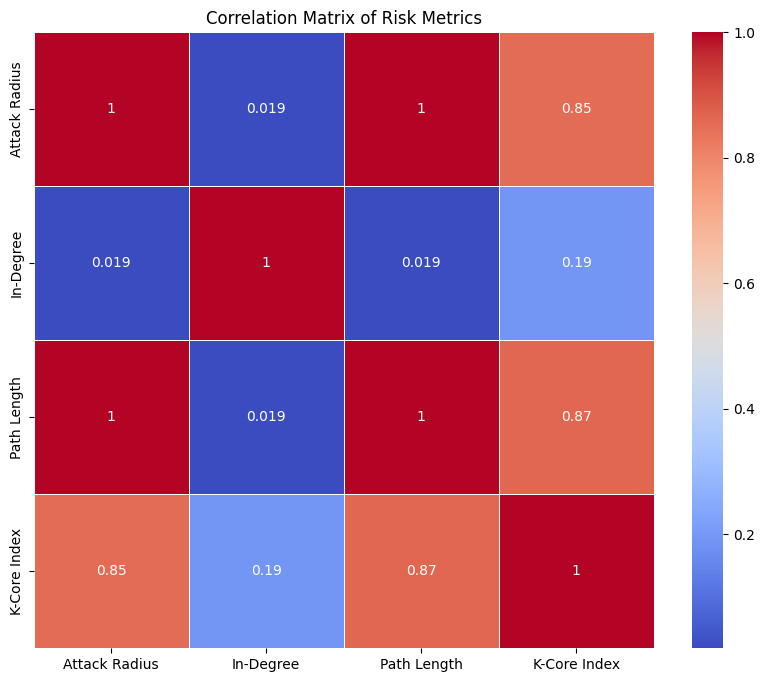

In [ ]:
common_df_numeric = combined_df.drop(columns=['Node'])
# Compute the correlation matrix
correlation_matrix = common_df_numeric.corr()

# Visualize the correlation matrix using a heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', linewidths=0.5)
plt.title('Correlation Matrix of Risk Metrics')
plt.show()

In [ ]:
# Merge vulnerability data with source and build phase data
combined_df = combined_df.merge(vuln_df, left_on='Node', right_on='Packages', how='left', indicator=True)

combined_df['is_vulnerable'] = combined_df['_merge'] == 'both'

# Drop the '_merge' column
combined_df.drop(columns=['_merge'], inplace=True)

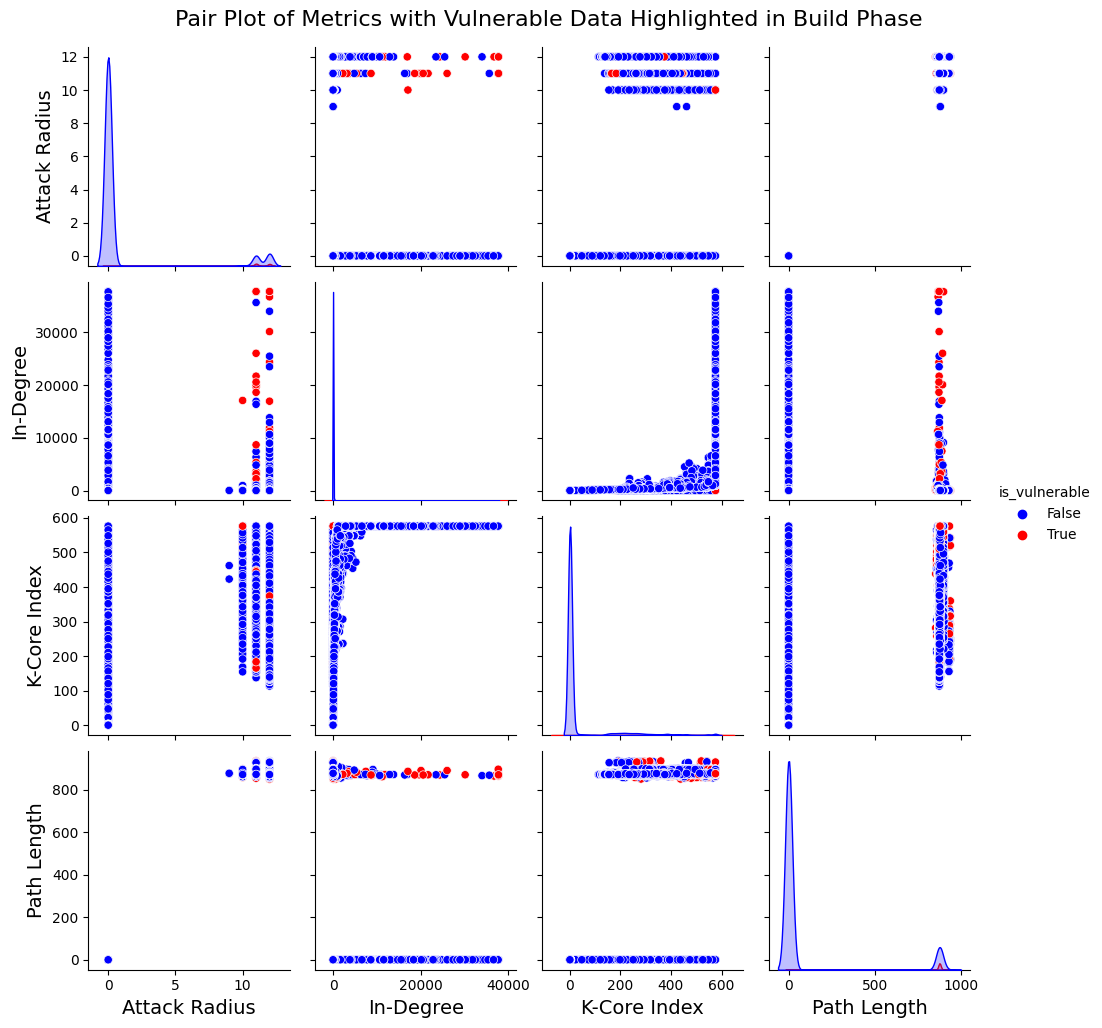

In [ ]:
# Create the pair plot with increased font sizes
pairplot = sns.pairplot(
    combined_df,
    vars=metrics,
    hue='is_vulnerable',
    palette={False: 'blue', True: 'red'},
)

# Increase the font size of the axis labels
for ax in pairplot.axes.flatten():
    ax.set_xlabel(ax.get_xlabel(), fontsize=14)
    ax.set_ylabel(ax.get_ylabel(), fontsize=14)

# Increase the font size of the overall title
plt.suptitle('Pair Plot of Metrics with Vulnerable Data Highlighted in Build Phase', y=1.02, fontsize=16)

# Show the plot
plt.show()

### compare the medians of vulnerables and non-vulnerables. do box plots. correlation b/w pop vs attack.

Comparison of Medians:
          Metric  Median (Vulnerable)  Median (Non-Vulnerable)
0  Attack Radius                 11.0                      0.0
1      In-Degree                  1.0                      1.0
2   K-Core Index                342.0                      1.0
3    Path Length                872.0                      0.0


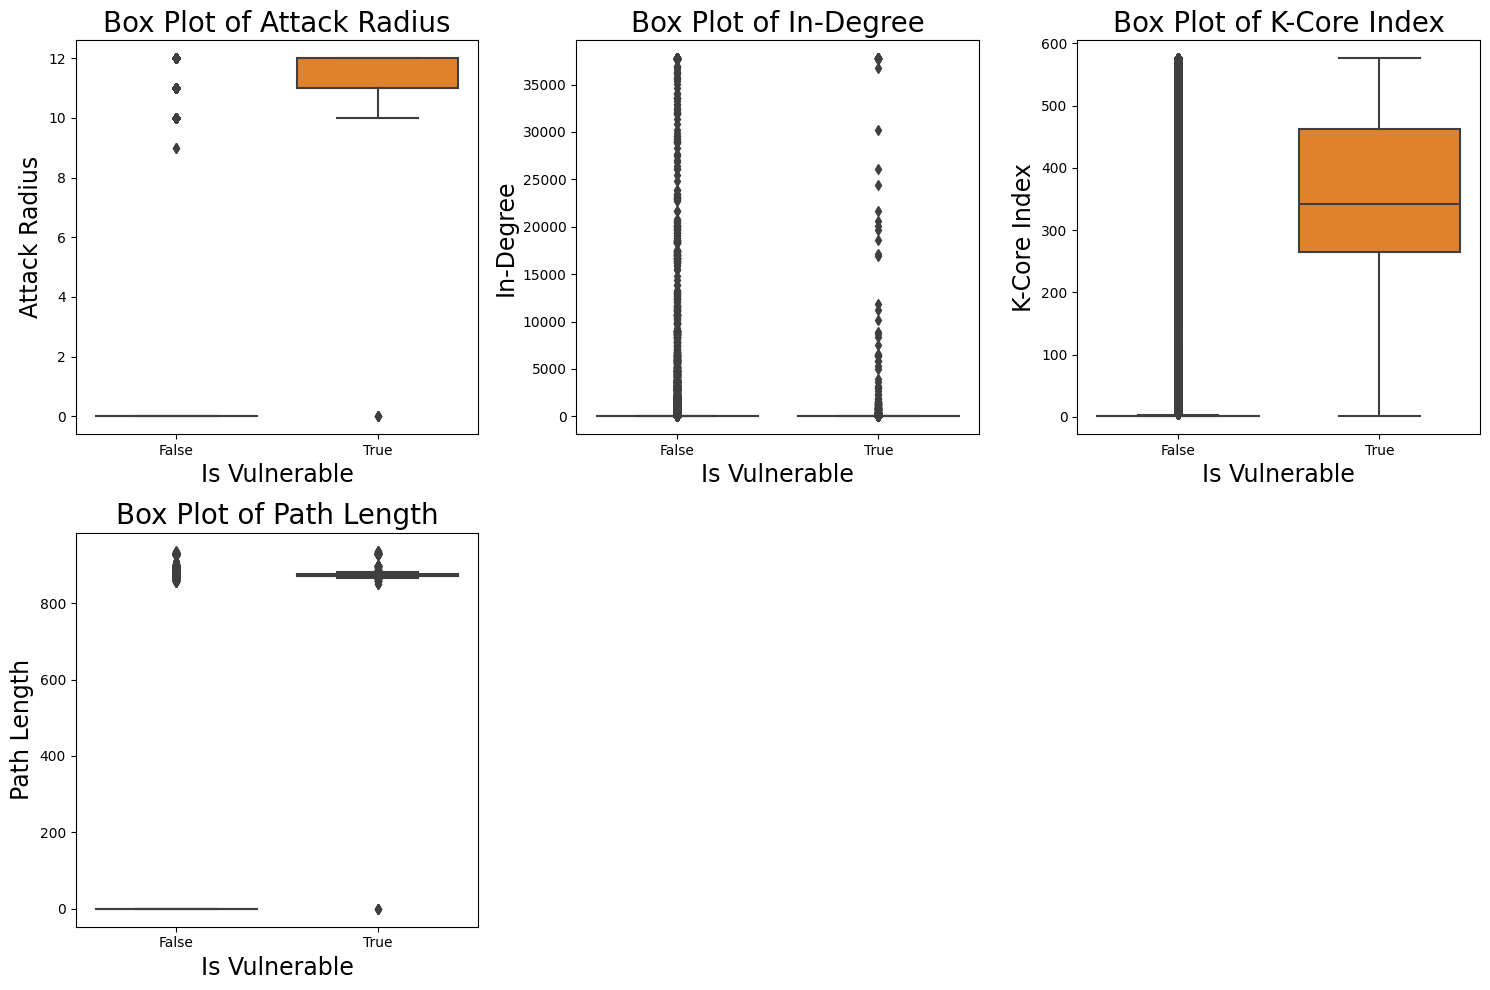

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import pearsonr

# Assuming 'combined_df' is your DataFrame containing the risk metrics data

# Calculate and compare the medians for vulnerable and non-vulnerable packages
vulnerable = combined_df[combined_df['is_vulnerable'] == 1]
non_vulnerable = combined_df[combined_df['is_vulnerable'] == 0]
# metrics = ['Attack Radius', 'In-Degree', 'Betweenness Centrality', 'Core Value', 'Longest Path Length']

median_comparison = pd.DataFrame({
    'Metric': metrics,
    'Median (Vulnerable)': [vulnerable[metric].median() for metric in metrics],
    'Median (Non-Vulnerable)': [non_vulnerable[metric].median() for metric in metrics]
})

print("Comparison of Medians:")
print(median_comparison)

# Create box plots for each risk metric
plt.figure(figsize=(15, 10))
for i, metric in enumerate(metrics):
    plt.subplot( 2,3, i+1)
    sns.boxplot(x='is_vulnerable', y=metric, data=combined_df)
    plt.title(f'Box Plot of {metric}',fontsize=20 )
    plt.xlabel('Is Vulnerable', fontsize=17)
    plt.ylabel(metric, fontsize=17)

plt.tight_layout()
plt.show()


In [ ]:
common_pop = pd.merge(vuln_df, pop_df, left_on='Packages', right_on='name', how='inner')
print(common_pop.shape)

(2480, 9)


In [ ]:
common_pop = pd.merge(combined_df, pop_df, left_on='Node', right_on='name', how='inner').fillna(0)
print(common_pop.shape)
print(combined_df.shape)

(91956, 15)
(347475, 7)


In [ ]:
pop_df.head()

,rank,name,inst,vote,old,recent,no-files,maintainer
0,1,adduser,234785,211590,4924,18233,38,Debian Adduser Developers
1,2,libacl1,234785,214251,2906,17588,40,Guillem Jover
2,3,tar,234785,213292,3464,17986,43,Janos Lenart
3,4,passwd,234784,213145,3410,18191,38,Shadow Package Maintainers
4,5,debconf,234782,214125,2631,17996,30,Debconf Developers


In [ ]:
pop_df.describe()

,rank,inst,vote,old,recent,no-files
count,196176.000000,196176.000000,196176.000000,196176.000000,196176.000000,196176.000000
mean,98088.500000,1649.625285,568.080239,500.780151,151.937566,428.827329
std,56631.277542,12764.023097,6830.080624,4805.629262,1452.011026,4926.530059
min,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,49044.750000,1.000000,0.000000,0.000000,0.000000,0.000000
50%,98088.500000,5.000000,0.000000,1.000000,0.000000,0.000000
75%,147132.250000,42.000000,3.000000,10.000000,1.000000,3.000000
max,196176.000000,234785.000000,216900.000000,190955.000000,51393.000000,233134.000000


#### Proposition: Packages critical to the functionality(used more) are more likely to have high propagation costs, as a compromise in such a package could impact a larger portion of the supply chain.

In [ ]:
import pandas as pd

# Assuming 'pop_df' is your DataFrame

# Define a threshold for 'inst' values
threshold = 230000

# Create a new column to indicate if 'inst' is high or not
common_pop['is_high_inst'] = common_pop['inst'] > threshold

# List of metrics to compare
# metrics = ['Attack Radius', 'Core Value', 'In-Degree', 'Betweenness Centrality']

# Calculate statistics for high inst packages
high_inst_stats = common_pop[common_pop['is_high_inst']][metrics].describe()

# Calculate statistics for non-high inst packages
# non_high_inst_stats = common_pops[~common_pops['is_high_inst']][metrics].describe()

# Print the statistics
print("Statistics for High 'inst' Packages:")
print(high_inst_stats)

Statistics for High 'inst' Packages:
       Attack Radius     In-Degree  K-Core Index  Path Length
count     130.000000    130.000000    130.000000   130.000000
mean        4.638462  19364.730769    467.515385   341.876923
std         5.801635  16490.549275    186.577425   427.150537
min         0.000000      1.000000      1.000000     0.000000
25%         0.000000    289.500000    370.000000     0.000000
50%         0.000000  16864.500000    576.000000     0.000000
75%        12.000000  37772.000000    576.000000   871.000000
max        12.000000  37772.000000    576.000000   892.000000


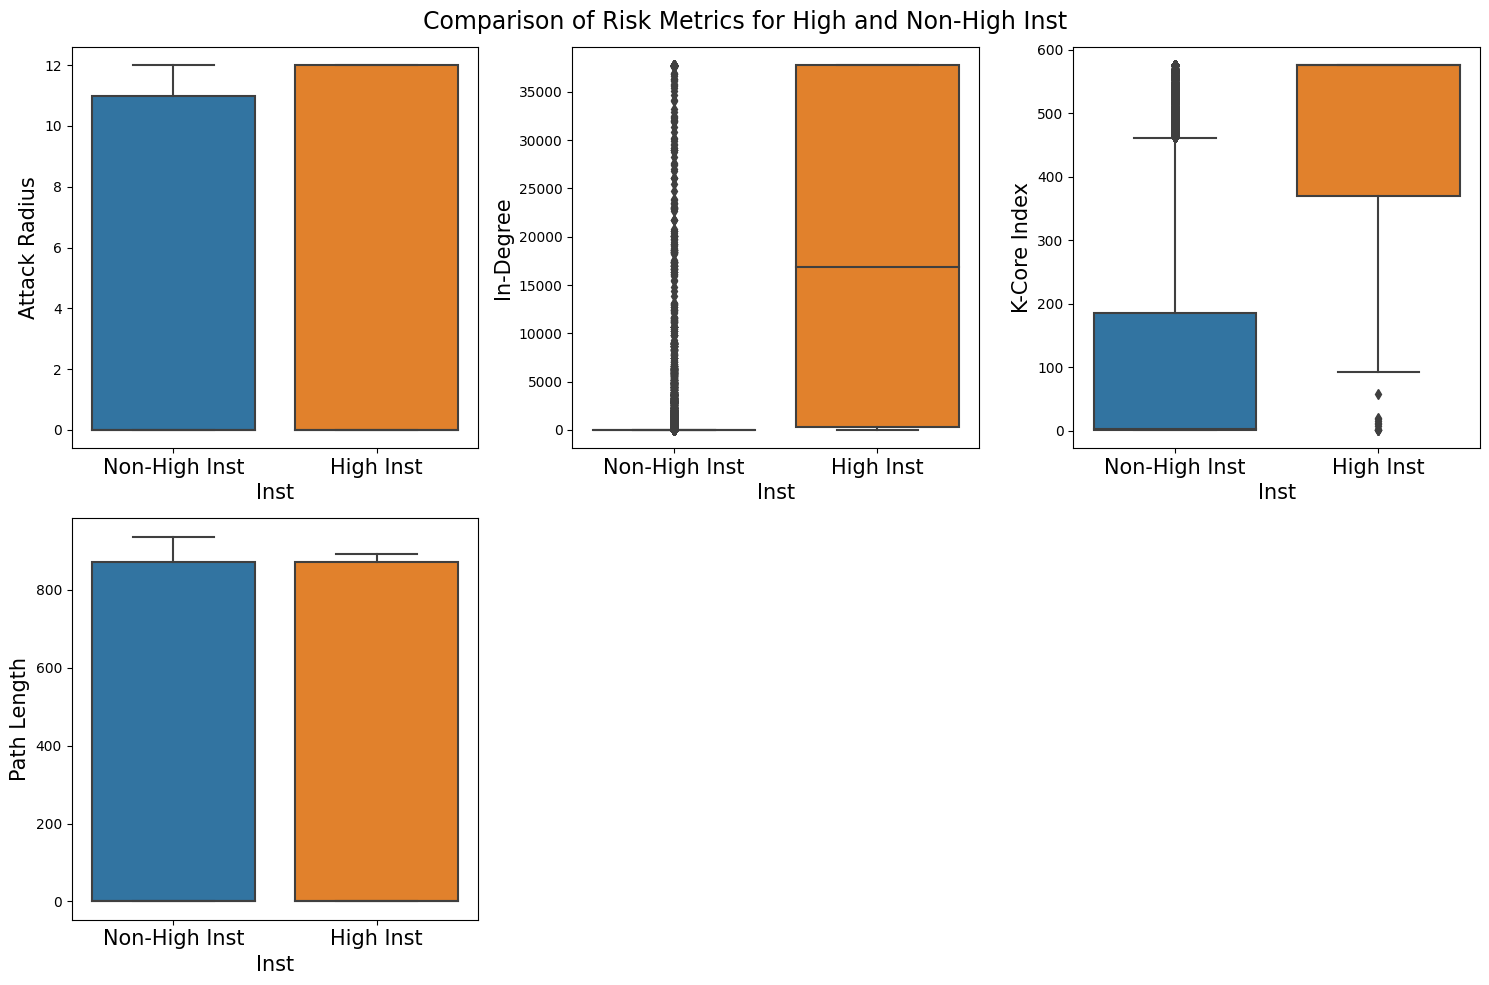

In [ ]:
threshold = 230000

# Create a new column to indicate if 'vote' is high or not
common_pop['is_high_inst'] = common_pop['inst'] > threshold

# Melt the DataFrame for seaborn's boxplot function
melted_df = pd.melt(common_pop, id_vars=['is_high_inst'], value_vars=metrics, var_name='metric', value_name='value')

# Set up the subplots
num_metrics = len(metrics)
fig, axes = plt.subplots(2, 3, figsize=(15, 10))

# Create a box plot for each metric
for i, metric in enumerate(metrics):
    sns.boxplot(x='is_high_inst', y='value', data=melted_df[melted_df['metric'] == metric], ax=axes.flat[i])
    # axes.flat[i].set_title(f'Comparison of {metric}', fontsize=15)
    axes.flat[i].set_xlabel('Inst', fontsize=15)
    axes.flat[i].set_ylabel(metric, fontsize=15)
    axes.flat[i].set_xticklabels(['Non-High Inst', 'High Inst'], fontsize=15)

# Remove the extra box at the end
for j in range(num_metrics, len(axes.flat)):
    fig.delaxes(axes.flat[j])

# Set title for all plots at once
fig.suptitle('Comparison of Risk Metrics for High and Non-High Inst', fontsize=17)

plt.tight_layout()
plt.show()


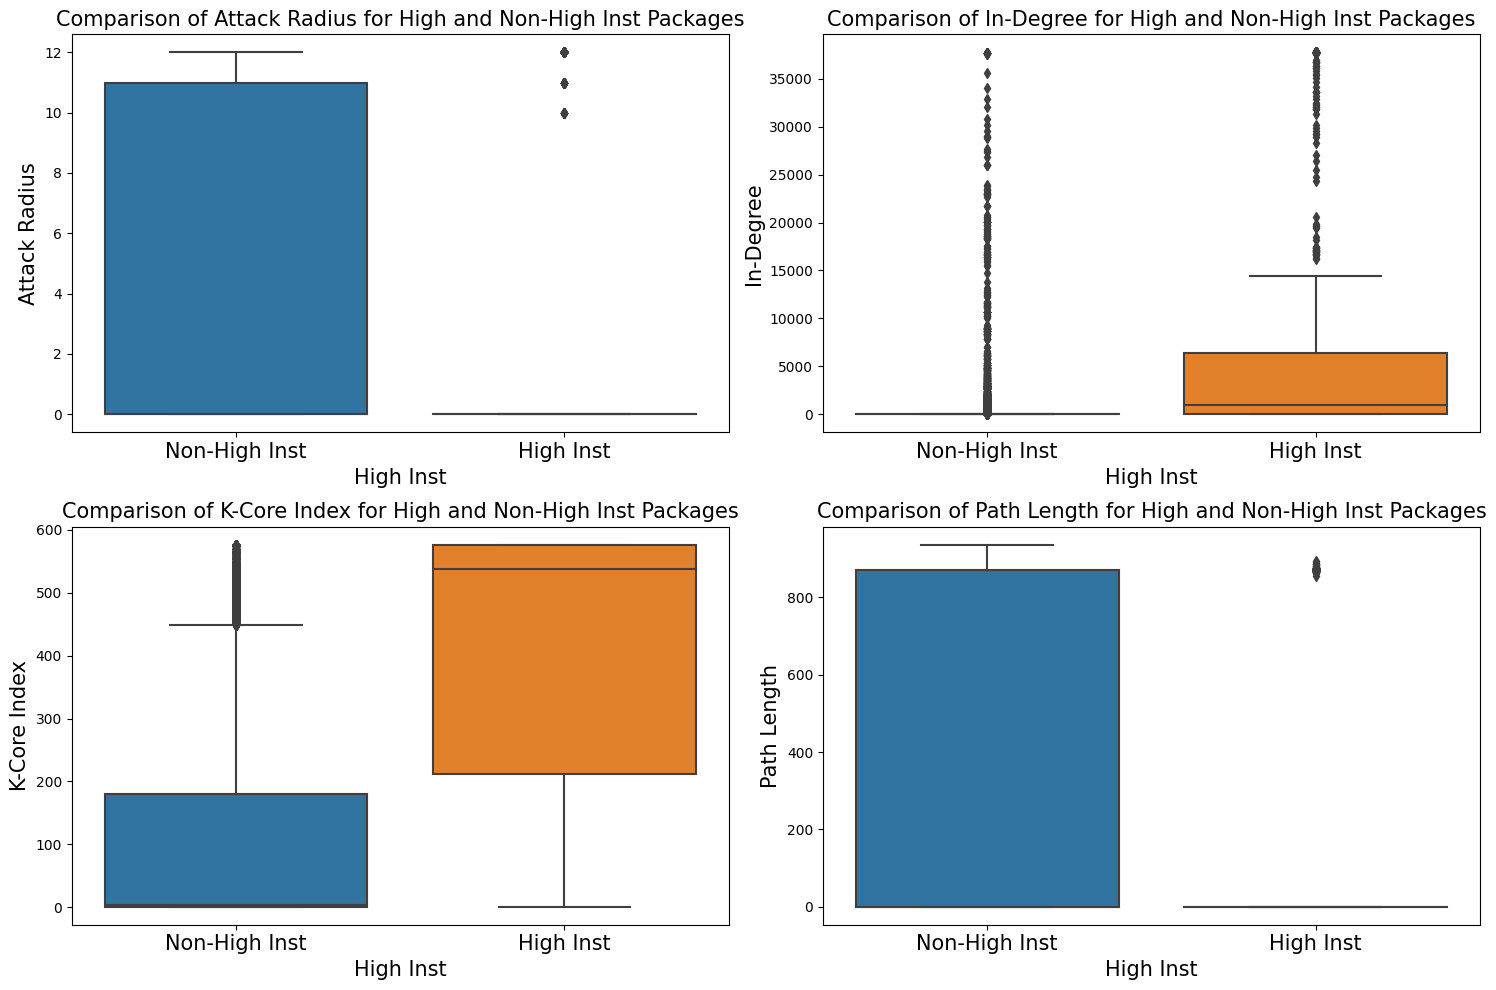

In [ ]:
common_pop_sorted = common_pop.sort_values(by='inst', ascending=False)
top_10_threshold = np.percentile(common_pop['inst'], 99)
# Create a new column to indicate if 'vote' is high or not
common_pop['is_high_inst'] = common_pop['inst'] > top_10_threshold

# Melt the DataFrame for seaborn's boxplot function
melted_df = pd.melt(common_pop, id_vars=['is_high_inst'], value_vars=metrics, var_name='metric', value_name='value')

# Set up the subplots
num_metrics = len(metrics)
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Create a box plot for each metric
for i, metric in enumerate(metrics):
    sns.boxplot(x='is_high_inst', y='value', data=melted_df[melted_df['metric'] == metric], ax=axes.flat[i])
    axes.flat[i].set_title(f'Comparison of {metric} for High and Non-High Inst Packages', fontsize=15)
    axes.flat[i].set_xlabel('High Inst', fontsize=15)
    axes.flat[i].set_ylabel(metric, fontsize=15)
    axes.flat[i].set_xticklabels(['Non-High Inst', 'High Inst'], fontsize=15)

plt.tight_layout()
plt.show()

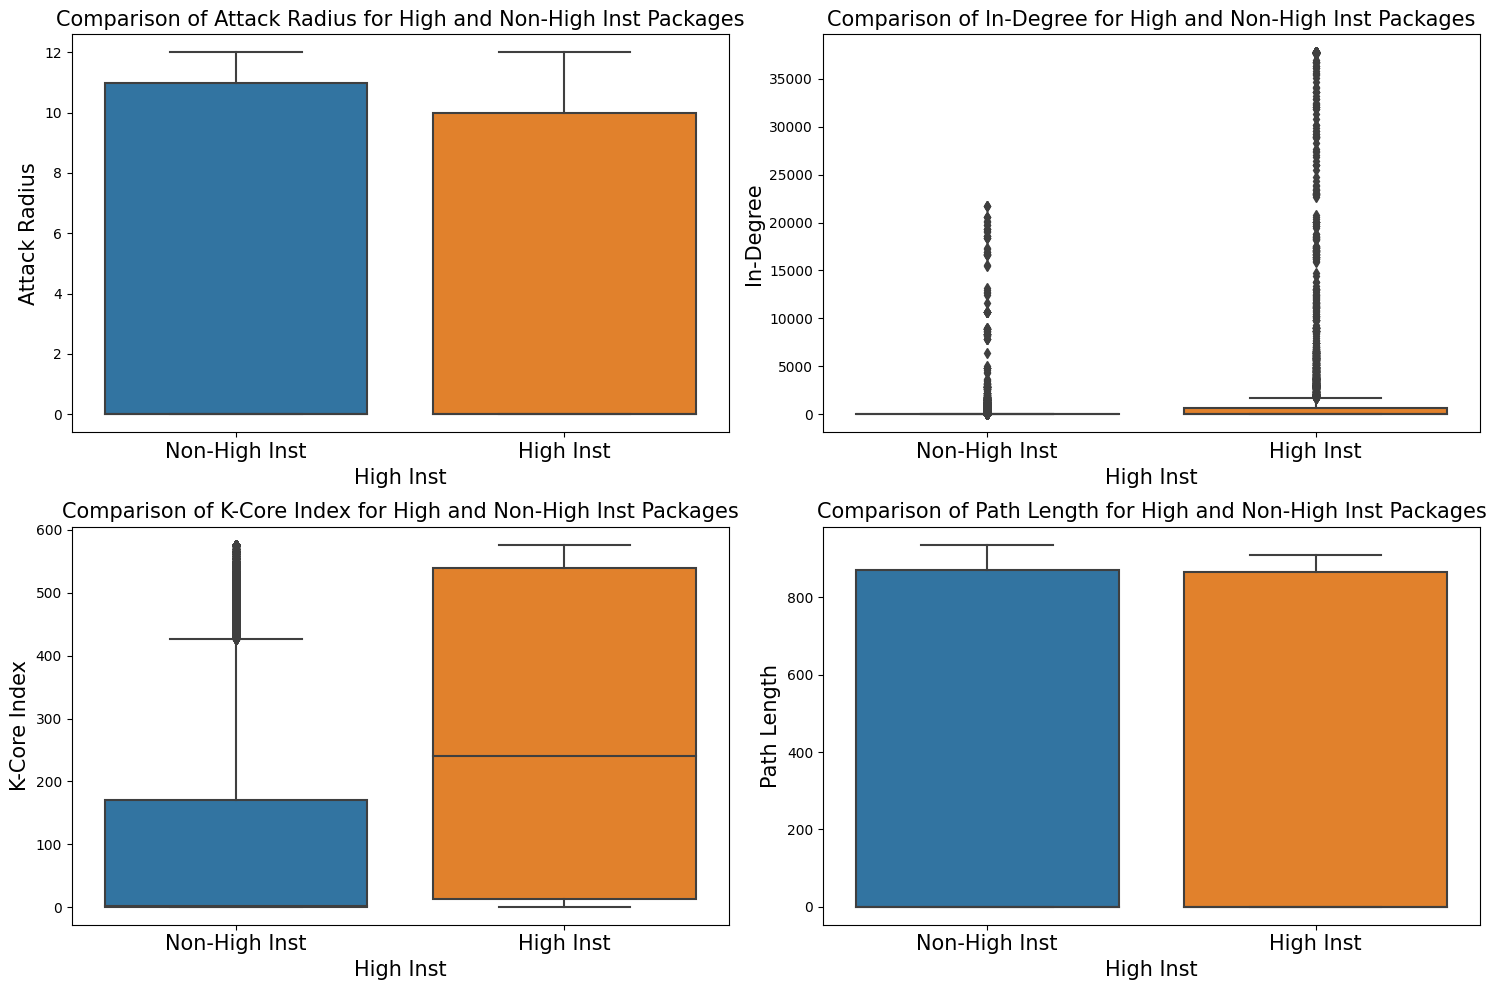

In [ ]:
common_pop_sorted = common_pop.sort_values(by='inst', ascending=False)
top_10_threshold = np.percentile(common_pop['inst'], 95)
# Create a new column to indicate if 'vote' is high or not
common_pop['is_high_inst'] = common_pop['inst'] > top_10_threshold

# Melt the DataFrame for seaborn's boxplot function
melted_df = pd.melt(common_pop, id_vars=['is_high_inst'], value_vars=metrics, var_name='metric', value_name='value')

# Set up the subplots
num_metrics = len(metrics)
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Create a box plot for each metric
for i, metric in enumerate(metrics):
    sns.boxplot(x='is_high_inst', y='value', data=melted_df[melted_df['metric'] == metric], ax=axes.flat[i])
    axes.flat[i].set_title(f'Comparison of {metric} for High and Non-High Inst Packages', fontsize=15)
    axes.flat[i].set_xlabel('High Inst', fontsize=15)
    axes.flat[i].set_ylabel(metric, fontsize=15)
    axes.flat[i].set_xticklabels(['Non-High Inst', 'High Inst'], fontsize=15)

plt.tight_layout()
plt.show()

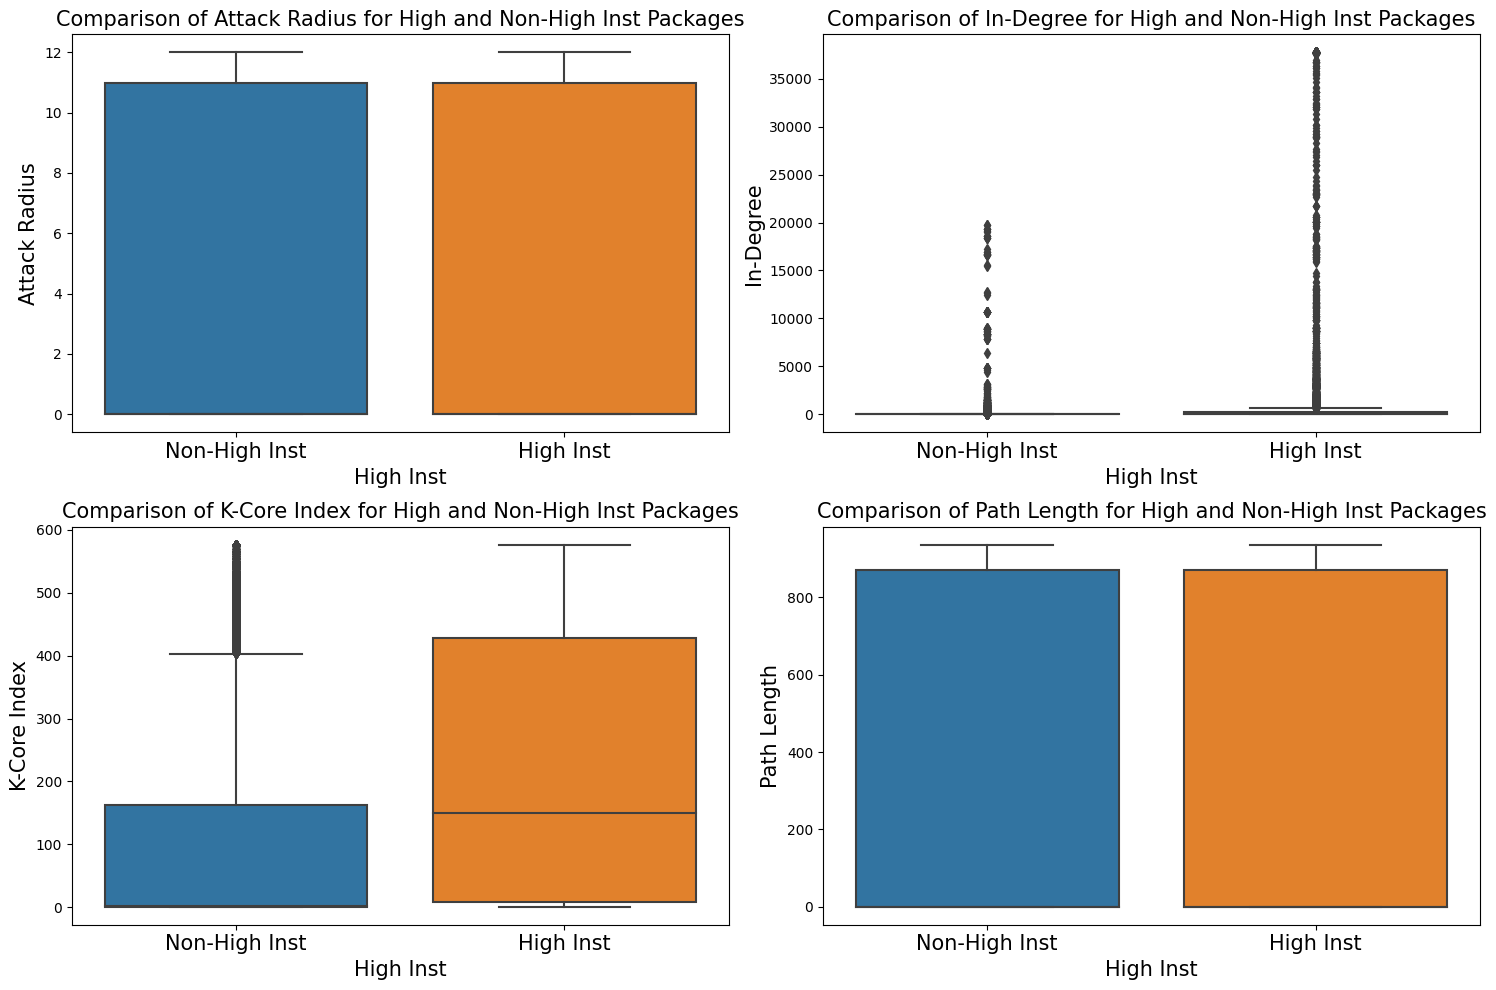

In [ ]:
common_pop_sorted = common_pop.sort_values(by='inst', ascending=False)
top_10_threshold = np.percentile(common_pop['inst'], 90)
# Create a new column to indicate if 'vote' is high or not
common_pop['is_high_inst'] = common_pop['inst'] > top_10_threshold

# Melt the DataFrame for seaborn's boxplot function
melted_df = pd.melt(common_pop, id_vars=['is_high_inst'], value_vars=metrics, var_name='metric', value_name='value')

# Set up the subplots
num_metrics = len(metrics)
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Create a box plot for each metric
for i, metric in enumerate(metrics):
    sns.boxplot(x='is_high_inst', y='value', data=melted_df[melted_df['metric'] == metric], ax=axes.flat[i])
    axes.flat[i].set_title(f'Comparison of {metric} for High and Non-High Inst Packages', fontsize=15)
    axes.flat[i].set_xlabel('High Inst', fontsize=15)
    axes.flat[i].set_ylabel(metric, fontsize=15)
    axes.flat[i].set_xticklabels(['Non-High Inst', 'High Inst'], fontsize=15)

plt.tight_layout()
plt.show()

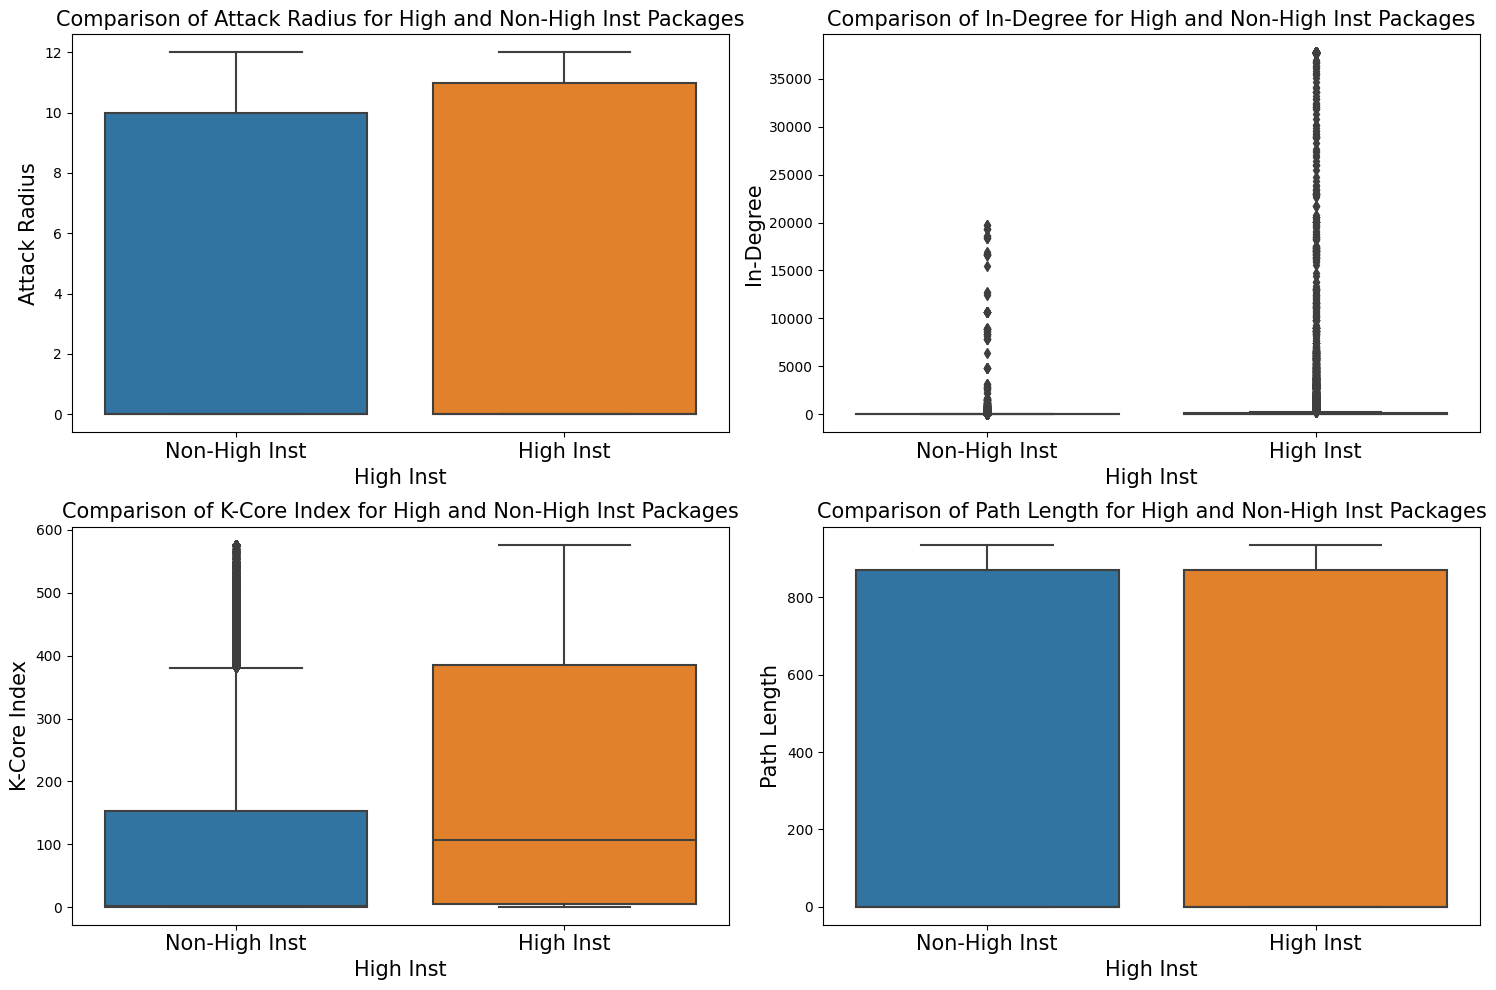

In [ ]:
common_pop_sorted = common_pop.sort_values(by='inst', ascending=False)
top_10_threshold = np.percentile(common_pop['inst'], 85)
# Create a new column to indicate if 'vote' is high or not
common_pop['is_high_inst'] = common_pop['inst'] > top_10_threshold

# Melt the DataFrame for seaborn's boxplot function
melted_df = pd.melt(common_pop, id_vars=['is_high_inst'], value_vars=metrics, var_name='metric', value_name='value')

# Set up the subplots
num_metrics = len(metrics)
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Create a box plot for each metric
for i, metric in enumerate(metrics):
    sns.boxplot(x='is_high_inst', y='value', data=melted_df[melted_df['metric'] == metric], ax=axes.flat[i])
    axes.flat[i].set_title(f'Comparison of {metric} for High and Non-High Inst Packages', fontsize=15)
    axes.flat[i].set_xlabel('High Inst', fontsize=15)
    axes.flat[i].set_ylabel(metric, fontsize=15)
    axes.flat[i].set_xticklabels(['Non-High Inst', 'High Inst'], fontsize=15)

plt.tight_layout()
plt.show()

In [ ]:
from scipy.stats import chi2_contingency, pearsonr, spearmanr, wilcoxon

# Perform Wilcoxon signed-rank test between all combinations of metrics
wilcoxon_results = []
# Chi-Square Test between metrics and inst (assuming both are categorical)
chi_square_results = []
for metric in metrics:
    contingency_table = pd.crosstab(common_pop[metric], common_pop['inst'])
    chi2, p, dof, ex = chi2_contingency(contingency_table)
    chi_square_results.append({'Metric': metric, 'Chi2 Statistic': chi2, 'p-value': p})
    stat, p_value = wilcoxon(common_pop[metric], common_pop['inst'])
    wilcoxon_results.append({
        'Metric': metric,
        'Statistic': stat,
        'p-value': p_value,
        'Significant': p_value < 0.05
    })

chi_square_df = pd.DataFrame(chi_square_results)
print("Chi-Square Test Results:")
print(chi_square_df)

wilcoxon_df = pd.DataFrame(wilcoxon_results)
print("\nWilcoxon Signed-Rank Test Results:")
print(wilcoxon_df)

# Correlation analysis between metrics and inst
correlation_results = []
for metric in metrics:
    pearson_corr, pearson_p = pearsonr(common_pop[metric], common_pop['inst'])
    spearman_corr, spearman_p = spearmanr(common_pop[metric], common_pop['inst'])
    correlation_results.append({
        'Metric': metric,
        'Pearson Correlation': pearson_corr,
        'Pearson p-value': pearson_p,
        'Spearman Correlation': spearman_corr,
        'Spearman p-value': spearman_p
    })

correlation_df = pd.DataFrame(correlation_results)
print("\nCorrelation Analysis Results:")
print(correlation_df)

    # if significant:
    #     print("The result is significant (p < 0.05), indicating a difference between the distributions.")
    # else:
    #     print("The result is not significant (p >= 0.05), indicating no difference between the distributions.")


Chi-Square Test Results:
          Metric  Chi2 Statistic        p-value
0  Attack Radius    4.728414e+04  1.291917e-167
1      In-Degree    1.203043e+08   0.000000e+00
2   K-Core Index    1.048117e+07   0.000000e+00
3    Path Length    1.522093e+06   0.000000e+00

Wilcoxon Signed-Rank Test Results:
          Metric     Statistic  p-value  Significant
0  Attack Radius  1.431212e+08      0.0         True
1      In-Degree  1.199036e+08      0.0         True
2   K-Core Index  1.001710e+09      0.0         True
3    Path Length  1.371997e+09      0.0         True

Correlation Analysis Results:
          Metric  Pearson Correlation  Pearson p-value  Spearman Correlation  \
0  Attack Radius            -0.001666         0.613521              0.196034   
1      In-Degree             0.493490         0.000000              0.401784   
2   K-Core Index             0.240164         0.000000              0.438456   
3    Path Length            -0.002144         0.515620              0.196706   

  

## Modeling Risks

In [ ]:
import pandas as pd
import numpy as np
from sklearn import linear_model
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from mlxtend.feature_selection import SequentialFeatureSelector
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import pandas as pd
import numpy as np
import statsmodels.api as sm

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score,confusion_matrix, classification_report
from sklearn.feature_selection import SequentialFeatureSelector
import statsmodels.api as sm

# Load your data into combined_df
# Example:
# combined_df = pd.read_csv('your_data.csv')

# Define the feature matrix and target variable
# X = combined_df[['Attack Radius', 'In-Degree', 'Betweenness Centrality', 'Core Value', 'Longest Path Length']]
X = combined_df[['Attack Radius', 'In-Degree', 'K-Core Index', 'Path Length']]
y = combined_df['is_vulnerable']

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Perform stepwise feature selection
sfs = SequentialFeatureSelector(LogisticRegression(max_iter=1000),
                                n_features_to_select='auto',
                                direction='forward',
                                scoring='accuracy',
                                cv=5)
sfs.fit(X_train, y_train)

# Get the selected features
selected_features = sfs.get_support(indices=True)
X_train_selected = X_train.iloc[:, selected_features]
X_test_selected = X_test.iloc[:, selected_features]

# Fit a logistic regression model using the selected features
logreg = LogisticRegression(max_iter=1000)
logreg.fit(X_train_selected, y_train)

# Make predictions using the test set
y_pred = logreg.predict(X_test_selected)

# Evaluate the model performance
accuracy = accuracy_score(y_test, y_pred)
print(f'Accuracy: {accuracy}')
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("Classification Report:\n", classification_report(y_test, y_pred))

Accuracy: 0.9897930796312462
Confusion Matrix:
 [[103169      3]
 [  1061     10]]
Classification Report:
               precision    recall  f1-score   support

       False       0.99      1.00      0.99    103172
        True       0.77      0.01      0.02      1071

    accuracy                           0.99    104243
   macro avg       0.88      0.50      0.51    104243
weighted avg       0.99      0.99      0.98    104243



In [ ]:
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import pandas as pd

# Assuming 'data' is your DataFrame containing the risk metrics data

# Split the data into independent variables (X) and dependent variable (y)
X = combined_df[['Attack Radius', 'In-Degree', 'K-Core Index', 'Path Length']]
y = combined_df['is_vulnerable']

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.4, random_state=42)

# Apply SMOTE to the training data
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

# Logistic Regression Model
logistic_model = LogisticRegression(max_iter=1000,class_weight='balanced')
logistic_model.fit(X_train_smote, y_train_smote)
y_pred_logistic = logistic_model.predict(X_test)

# Decision Tree Model
decision_tree_model = DecisionTreeClassifier(class_weight='balanced')
decision_tree_model.fit(X_train_smote, y_train_smote)
y_pred_dt = decision_tree_model.predict(X_test)

# Evaluate the models
print("Logistic Regression Model:")
print("Accuracy:", accuracy_score(y_test, y_pred_logistic))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_logistic))
print("Classification Report:\n", classification_report(y_test, y_pred_logistic))

Logistic Regression Model:
Accuracy: 0.9017267429311461
Confusion Matrix:
 [[123900  13656]
 [     3   1431]]
Classification Report:
               precision    recall  f1-score   support

       False       1.00      0.90      0.95    137556
        True       0.09      1.00      0.17      1434

    accuracy                           0.90    138990
   macro avg       0.55      0.95      0.56    138990
weighted avg       0.99      0.90      0.94    138990



In [ ]:
print("\nDecision Tree Model:")
print("Accuracy:", accuracy_score(y_test, y_pred_dt))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_dt))
print("Classification Report:\n", classification_report(y_test, y_pred_dt))


Decision Tree Model:
Accuracy: 0.9473343406000432
Confusion Matrix:
 [[130880   6676]
 [   644    790]]
Classification Report:
               precision    recall  f1-score   support

       False       1.00      0.95      0.97    137556
        True       0.11      0.55      0.18      1434

    accuracy                           0.95    138990
   macro avg       0.55      0.75      0.58    138990
weighted avg       0.99      0.95      0.96    138990



In [ ]:
from imblearn.over_sampling import BorderlineSMOTE
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.model_selection import train_test_split

# Apply Borderline-SMOTE to the training data
smote = BorderlineSMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

# Random Forest Model
rf_model = RandomForestClassifier(random_state=42)
rf_model.fit(X_train_smote, y_train_smote)
y_pred_rf = rf_model.predict(X_test)

# Evaluate the model
print("Random Forest Model:")
print("Accuracy:", accuracy_score(y_test, y_pred_rf))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_rf))
print("Classification Report:\n", classification_report(y_test, y_pred_rf))



Random Forest Model:
Accuracy: 0.952543348442334
Confusion Matrix:
 [[131644   5912]
 [   684    750]]
Classification Report:
               precision    recall  f1-score   support

       False       0.99      0.96      0.98    137556
        True       0.11      0.52      0.19      1434

    accuracy                           0.95    138990
   macro avg       0.55      0.74      0.58    138990
weighted avg       0.99      0.95      0.97    138990



In [ ]:
from sklearn.model_selection import cross_val_score, cross_val_predict, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from imblearn.over_sampling import BorderlineSMOTE
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, make_scorer
import pandas as pd

# Assuming 'X_train' and 'y_train' are your training features and target variable

# Apply Borderline-SMOTE to the data
smote = BorderlineSMOTE(random_state=42)
X_resampled, y_resampled = smote.fit_resample(X_train, y_train)

# Combine the resampled features and target variable into a single DataFrame
resampled_df = pd.DataFrame(X_resampled, columns=X_train.columns)
resampled_df['Target'] = y_resampled

# Create a Random Forest Classifier
rf_classifier = RandomForestClassifier(random_state=42)

# Create a stratified k-fold cross-validator
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Convert the accuracy_score metric to a scorer
accuracy_scorer = make_scorer(accuracy_score)

# Perform cross-validation
# cv_results = cross_val_score(rf_classifier, X_resampled, y_resampled, cv=cv, scoring=accuracy_scorer)
# print("Cross-validation scores:", cv_results)

# Perform cross-validated predictions
y_pred = cross_val_predict(rf_classifier, X_resampled, y_resampled, cv=cv)

# Evaluate the predictions
print("Random Forest Classifier on resampled data")
print("Accuracy:", accuracy_score(y_resampled, y_pred))
print("Confusion Matrix:\n", confusion_matrix(y_resampled, y_pred))
print("Classification Report:\n", classification_report(y_resampled, y_pred))

# Fit the classifier to the entire resampled dataset
rf_classifier.fit(X_resampled, y_resampled)

Random Forest Classifier on resampled data
Accuracy: 0.9727849143610013
Confusion Matrix:
 [[195939  10509]
 [   728 205720]]
Classification Report:
               precision    recall  f1-score   support

       False       1.00      0.95      0.97    206448
        True       0.95      1.00      0.97    206448

    accuracy                           0.97    412896
   macro avg       0.97      0.97      0.97    412896
weighted avg       0.97      0.97      0.97    412896



RandomForestClassifier(random_state=42)

In [ ]:
# # Identify misclassified samples
# misclassified_indices = [index for index, (actual, predicted) in enumerate(zip(y_resampled, y_pred)) if actual != predicted]
# misclassified_samples = resampled_df.iloc[misclassified_indices]

# # Filter misclassified samples where actual label is True (1)
# misclassified_true_samples = misclassified_samples[misclassified_samples['Target'] == 1]
# unique_misclassified_true_samples = misclassified_true_samples.drop_duplicates()

# print("Misclassified samples where actual label is True:")
# print(unique_misclassified_true_samples)
# misclassified_samples.to_csv('misclassified_samples.csv', index=False)
# unique_misclassified_true_samples.to_csv('misclassified_vulnerable_samples.csv', index=False)
# # print("Actual labels of misclassified samples where actual label is True:")
# # print(misclassified_true_samples['Target'])
# # print("Predicted labels of misclassified samples where actual label is True:")
# # print(pd.Series(y_pred).iloc[misclassified_indices][misclassified_true_samples.index].values)

Misclassified samples where actual label is True:
        Attack Radius  In-Degree  K-Core Index  Path Length  Target
46                 11          0           303          873    True
166                11          2           343          876    True
1872               12          0           299          876    True
3268               11          1           430          878    True
3659               12        730           548          872    True
...               ...        ...           ...          ...     ...
406453             12          1           230          928    True
406785             12          7           321          872    True
408004             11          0           505          874    True
408474             11          1           446          896    True
408483             11          1           313          929    True

[429 rows x 5 columns]


In [ ]:
# Identify correctly classified samples
correctly_classified_indices = [index for index, (actual, predicted) in enumerate(zip(y_resampled, y_pred)) if actual == predicted]
correctly_classified_samples = resampled_df.iloc[correctly_classified_indices]

# Filter correctly classified samples where actual label is True (1)
correctly_classified_true_samples = correctly_classified_samples[correctly_classified_samples['Target'] == 1]

# Get unique correctly classified samples
unique_correctly_classified_true_samples = correctly_classified_true_samples.drop_duplicates()
unique_misclassified_true_samples.to_csv('vulnerable_samples.csv', index=False)

print("Unique correctly classified samples where actual label is True:")
print(unique_correctly_classified_true_samples)

Unique correctly classified samples where actual label is True:
        Attack Radius  In-Degree  K-Core Index  Path Length  Target
80                 12          1           382          873    True
206                11          0           331          875    True
330                11          1           344          872    True
504                11          1           548          878    True
858                11          2           414          873    True
...               ...        ...           ...          ...     ...
412787             11        349           462          873    True
412797             11        175           392          874    True
412837             11        915           513          876    True
412869             11      20005           576          870    True
412879             11        474           497          859    True

[16720 rows x 5 columns]


In [ ]:
shape_of_vulnerable_samples = combined_df[combined_df['is_vulnerable'] == 1].shape
print("Shape of combined_df where is_vulnerable is equal to 1:", shape_of_vulnerable_samples)

Shape of combined_df where is_vulnerable is equal to 1: (3471, 7)


In [ ]:
from sklearn.model_selection import cross_val_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, KFold
from imblearn.over_sampling import BorderlineSMOTE, ADASYN
from sklearn.metrics import make_scorer, accuracy_score
from sklearn.model_selection import cross_val_predict

# Assuming 'X' and 'y' are your features and target variable

# Apply Borderline-SMOTE or ADASYN to the data
smote = BorderlineSMOTE(random_state=42)
# smote = ADASYN(random_state=42)
X_resampled, y_resampled = smote.fit_resample(X_train, y_train)

# Create a Random Forest Classifier
rf_classifier = RandomForestClassifier(random_state=42)

# Create a stratified k-fold cross-validator
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# # Perform cross-validation
cv_results = cross_val_score(rf_classifier, X_resampled, y_resampled, cv=cv, scoring=make_scorer(accuracy_score))
print(cv_results)
# Perform cross-validated predictions
y_pred = cross_val_predict(rf_classifier, X_resampled, y_resampled, cv=cv)

# Evaluate the predictions
print("Random Forest Classifier on training data")
print("Accuracy:", accuracy_score(y_resampled, y_pred))
print("Confusion Matrix:\n", confusion_matrix(y_resampled, y_pred))
print("Classification Report:\n", classification_report(y_resampled, y_pred))

# Fit the classifier to the data
rf_classifier.fit(X_resampled, y_resampled)

feature_importance = rf_classifier.feature_importances_
# Assuming 'X' is your feature DataFrame
feature_importance_df = pd.DataFrame({'Feature': X_resampled.columns, 'Importance': feature_importance})
print(feature_importance_df)


[0.97616856 0.97587764 0.97689485 0.97750033 0.97676165]
Random Forest Classifier on training data
Accuracy: 0.9766406068356196
Confusion Matrix:
 [[197897   8551]
 [  1094 205354]]
Classification Report:
               precision    recall  f1-score   support

       False       0.99      0.96      0.98    206448
        True       0.96      0.99      0.98    206448

    accuracy                           0.98    412896
   macro avg       0.98      0.98      0.98    412896
weighted avg       0.98      0.98      0.98    412896

         Feature  Importance
0  Attack Radius    0.475501
1      In-Degree    0.020983
2   K-Core Index    0.215087
3    Path Length    0.288429


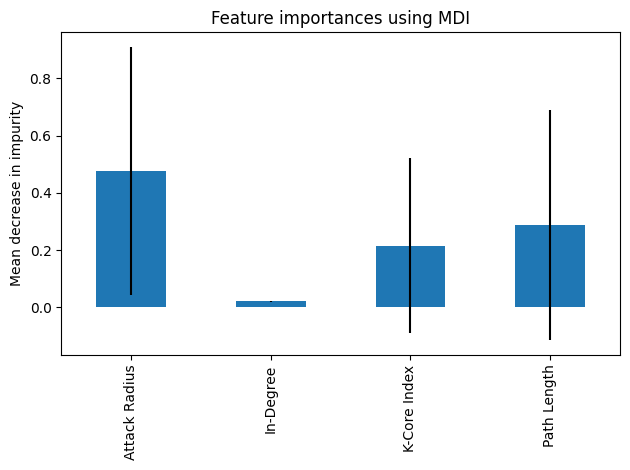

In [ ]:
forest_importances = pd.Series(feature_importance, index=X_resampled.columns)
std = np.std([tree.feature_importances_ for tree in rf_classifier.estimators_], axis=0)
fig, ax = plt.subplots()
forest_importances.plot.bar(yerr=std, ax=ax)
ax.set_title("Feature importances using MDI")
ax.set_ylabel("Mean decrease in impurity")
fig.tight_layout()

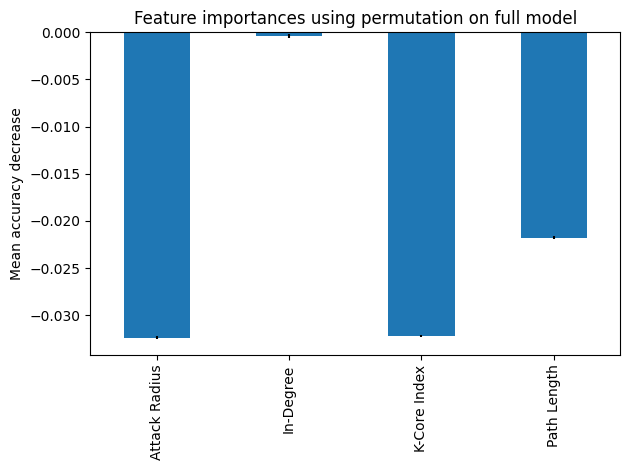

In [ ]:
from sklearn.inspection import permutation_importance

result = permutation_importance(
    rf_classifier, X_test, y_test, n_repeats=10, random_state=42, n_jobs=2
)
forest_importances = pd.Series(result.importances_mean, index=X_resampled.columns)
fig, ax = plt.subplots()
forest_importances.plot.bar(yerr=result.importances_std, ax=ax)
ax.set_title("Feature importances using permutation on full model")
ax.set_ylabel("Mean accuracy decrease")
fig.tight_layout()
plt.show()

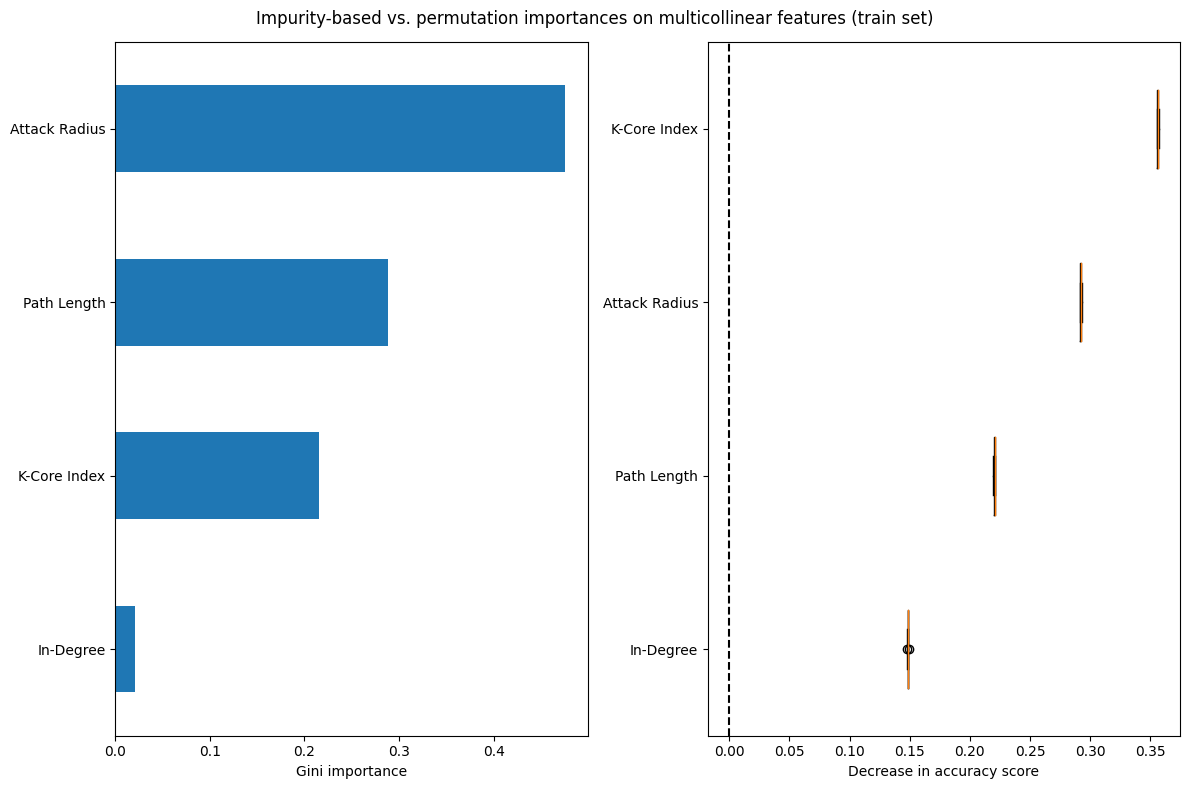

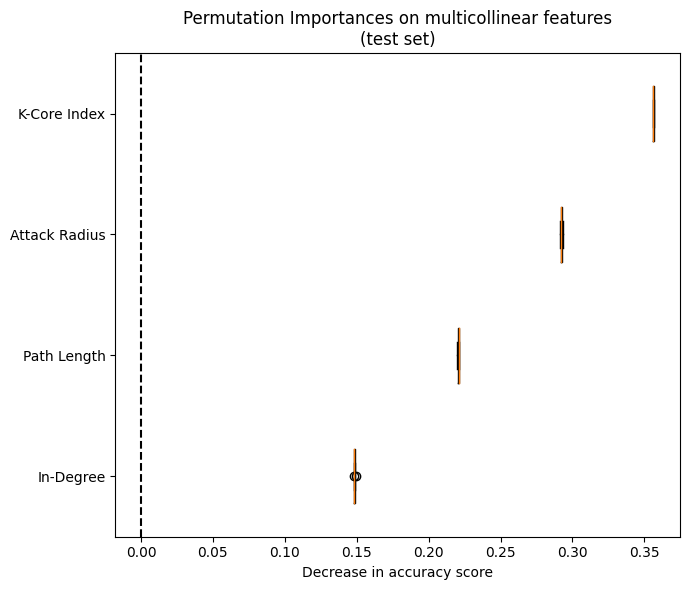

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.inspection import permutation_importance


def plot_permutation_importance(clf, X, y, ax):
    result = permutation_importance(clf, X, y, n_repeats=10, random_state=42, n_jobs=2)
    perm_sorted_idx = result.importances_mean.argsort()

    ax.boxplot(
        result.importances[perm_sorted_idx].T,
        vert=False,
        labels=X.columns[perm_sorted_idx],
    )
    ax.axvline(x=0, color="k", linestyle="--")
    return ax

mdi_importances = pd.Series(rf_classifier.feature_importances_, index=X_resampled.columns)
tree_importance_sorted_idx = np.argsort(rf_classifier.feature_importances_)
tree_indices = np.arange(0, len(rf_classifier.feature_importances_)) + 0.5

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 8))
mdi_importances.sort_values().plot.barh(ax=ax1)
ax1.set_xlabel("Gini importance")
plot_permutation_importance(rf_classifier, X_resampled, y_resampled, ax2)
ax2.set_xlabel("Decrease in accuracy score")
fig.suptitle(
    "Impurity-based vs. permutation importances on multicollinear features (train set)"
)
_ = fig.tight_layout()

fig, ax = plt.subplots(figsize=(7, 6))
plot_permutation_importance(rf_classifier, X_resampled, y_resampled, ax)
ax.set_title("Permutation Importances on multicollinear features\n(test set)")
ax.set_xlabel("Decrease in accuracy score")
_ = ax.figure.tight_layout()

#### Handling Multicollinear Features

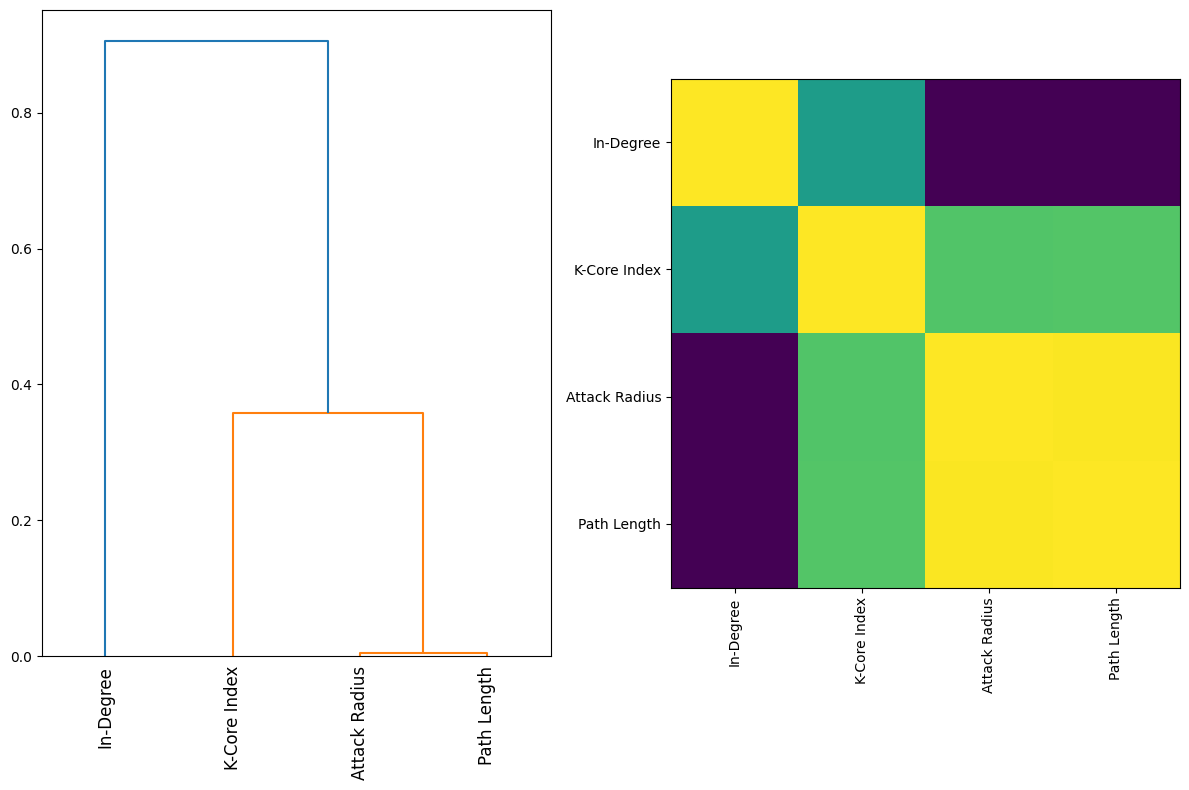

In [ ]:
from scipy.cluster import hierarchy
from scipy.spatial.distance import squareform
from scipy.stats import spearmanr

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 8))
corr = spearmanr(X).correlation

# Ensure the correlation matrix is symmetric
corr = (corr + corr.T) / 2
np.fill_diagonal(corr, 1)

# We convert the correlation matrix to a distance matrix before performing
# hierarchical clustering using Ward's linkage.
distance_matrix = 1 - np.abs(corr)
dist_linkage = hierarchy.ward(squareform(distance_matrix))
dendro = hierarchy.dendrogram(
    dist_linkage, labels=X.columns.to_list(), ax=ax1, leaf_rotation=90
)
dendro_idx = np.arange(0, len(dendro["ivl"]))

ax2.imshow(corr[dendro["leaves"], :][:, dendro["leaves"]])
ax2.set_xticks(dendro_idx)
ax2.set_yticks(dendro_idx)
ax2.set_xticklabels(dendro["ivl"], rotation="vertical")
ax2.set_yticklabels(dendro["ivl"])
_ = fig.tight_layout()

Baseline accuracy on test data with features removed: 0.99


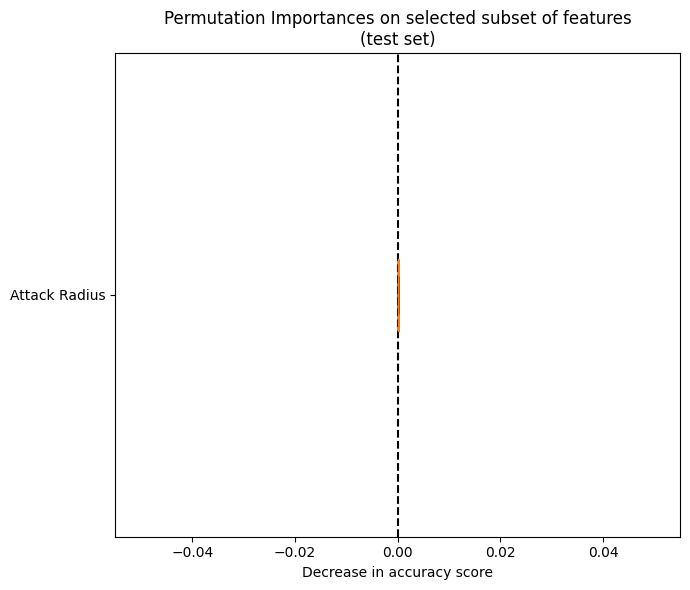

In [ ]:
from collections import defaultdict

cluster_ids = hierarchy.fcluster(dist_linkage, 1, criterion="distance")
cluster_id_to_feature_ids = defaultdict(list)
for idx, cluster_id in enumerate(cluster_ids):
    cluster_id_to_feature_ids[cluster_id].append(idx)
selected_features = [v[0] for v in cluster_id_to_feature_ids.values()]
selected_features_names = X.columns[selected_features]

X_train_sel = X_train[selected_features_names]
X_test_sel = X_test[selected_features_names]

clf_sel = RandomForestClassifier(n_estimators=100, random_state=42)
clf_sel.fit(X_train_sel, y_train)
print(
    "Baseline accuracy on test data with features removed:"
    f" {clf_sel.score(X_test_sel, y_test):.2}"
)

fig, ax = plt.subplots(figsize=(7, 6))
plot_permutation_importance(clf_sel, X_test_sel, y_test, ax)
ax.set_title("Permutation Importances on selected subset of features\n(test set)")
ax.set_xlabel("Decrease in accuracy score")
ax.figure.tight_layout()
plt.show()

In [ ]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Create a Gradient Boosting Classifier
gb_classifier = GradientBoostingClassifier(n_estimators=100, random_state=42)
# Fit the classifier to the data

# Perform cross-validated predictions
y_pred = cross_val_predict(gb_classifier, X_resampled, y_resampled, cv=cv)

# Evaluate the predictions
print("Gradient Boosting Classifier on training data")
print("Accuracy:", accuracy_score(y_resampled, y_pred))
print("Confusion Matrix:\n", confusion_matrix(y_resampled, y_pred))
print("Classification Report:\n", classification_report(y_resampled, y_pred))

gb_classifier.fit(X_resampled, y_resampled)

feature_importance = gb_classifier.feature_importances_
# Assuming 'X' is your feature DataFrame
feature_importance_df = pd.DataFrame({'Feature': X_resampled.columns, 'Importance': feature_importance})
print(feature_importance_df)

Gradient Boosting Classifier on training data
Accuracy: 0.9547900682011935
Confusion Matrix:
 [[188031  18417]
 [   250 206198]]
Classification Report:
               precision    recall  f1-score   support

       False       1.00      0.91      0.95    206448
        True       0.92      1.00      0.96    206448

    accuracy                           0.95    412896
   macro avg       0.96      0.95      0.95    412896
weighted avg       0.96      0.95      0.95    412896

         Feature  Importance
0  Attack Radius    0.960028
1      In-Degree    0.002627
2   K-Core Index    0.025366
3    Path Length    0.011979


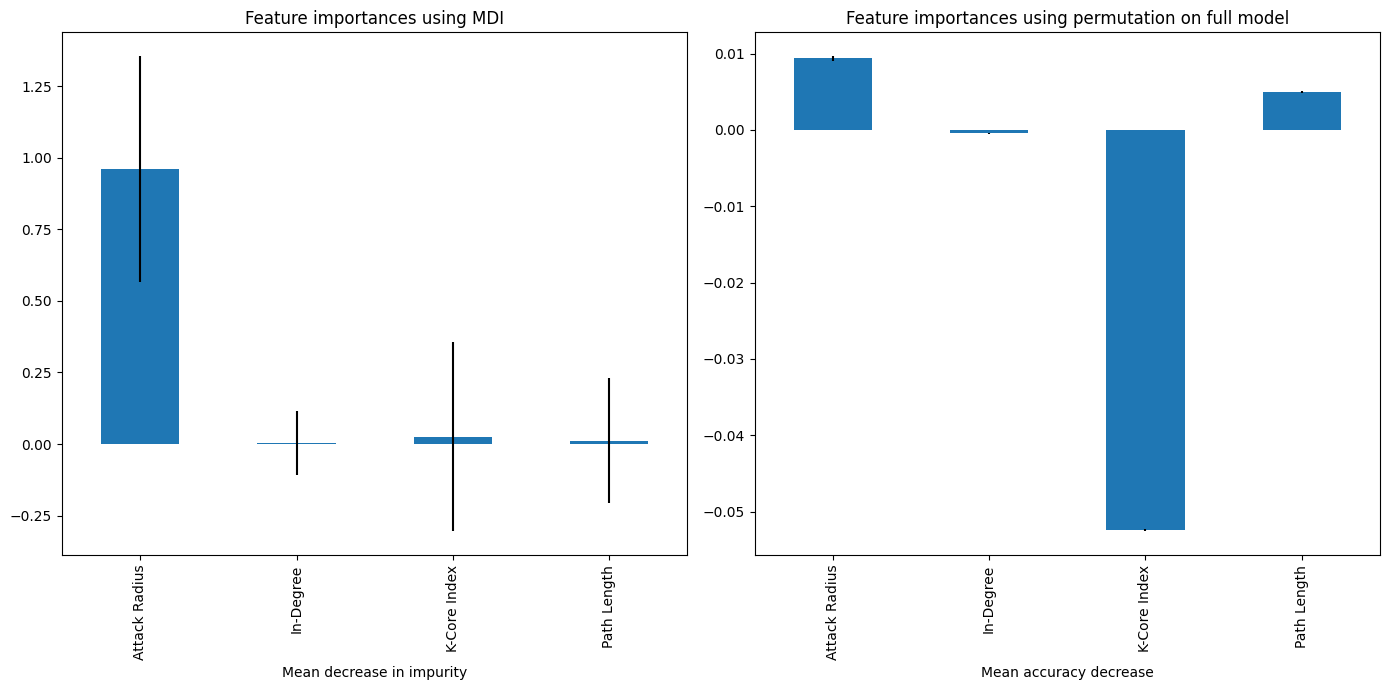

In [ ]:
# Feature importances using MDI
mdi_importances = pd.Series(gb_classifier.feature_importances_, index=X_resampled.columns)
std = np.std([tree[0].feature_importances_ for tree in gb_classifier.estimators_], axis=0)

# Feature importances using permutation importance
perm_importances = permutation_importance(gb_classifier, X_test, y_test, n_repeats=10, random_state=42, n_jobs=2)
perm_importances_mean = pd.Series(perm_importances.importances_mean, index=X_resampled.columns)
perm_importances_std = perm_importances.importances_std

# Plotting MDI vs Permutation Importances
fig, ax = plt.subplots(1, 2, figsize=(14, 7))

# Plot MDI importances
mdi_importances.plot.bar(yerr=std, ax=ax[0])
ax[0].set_title("Feature importances using MDI")
ax[0].set_xlabel("Mean decrease in impurity")

# Plot Permutation importances
perm_importances_mean.plot.bar(yerr=perm_importances_std, ax=ax[1])
ax[1].set_title("Feature importances using permutation on full model")
ax[1].set_xlabel("Mean accuracy decrease")

fig.tight_layout()
plt.show()

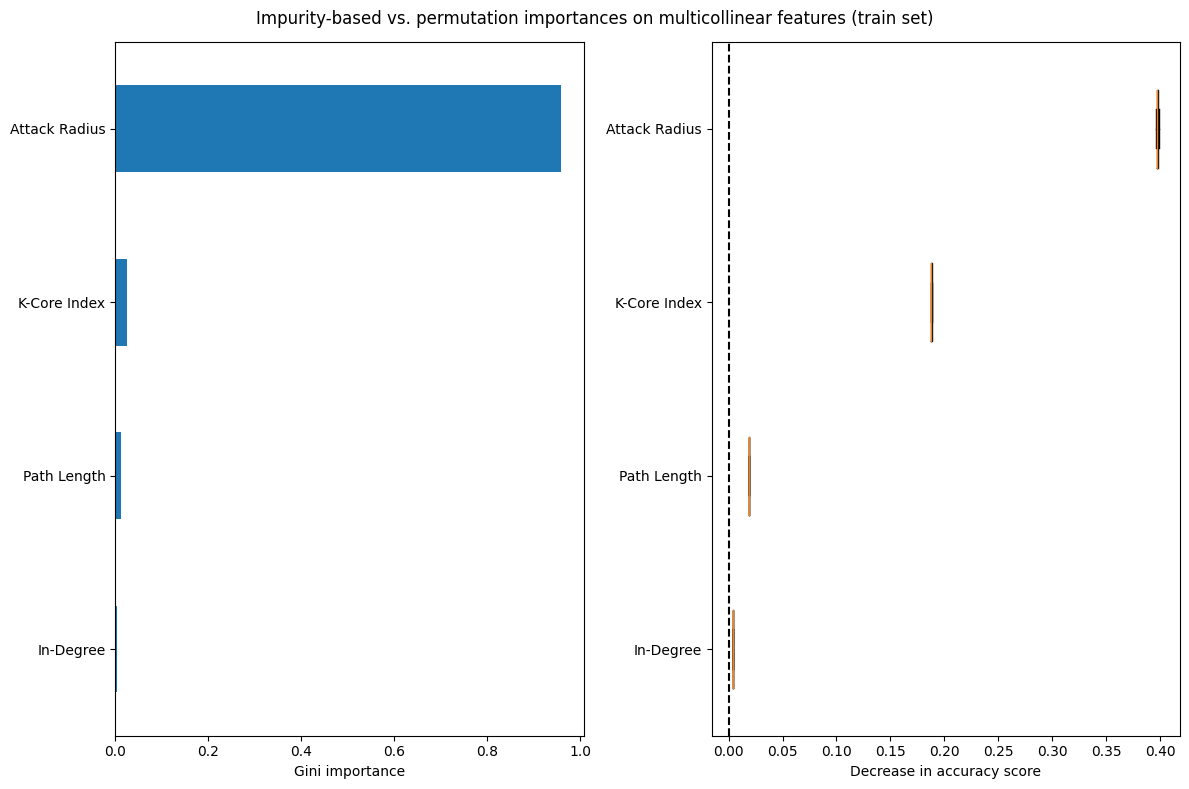

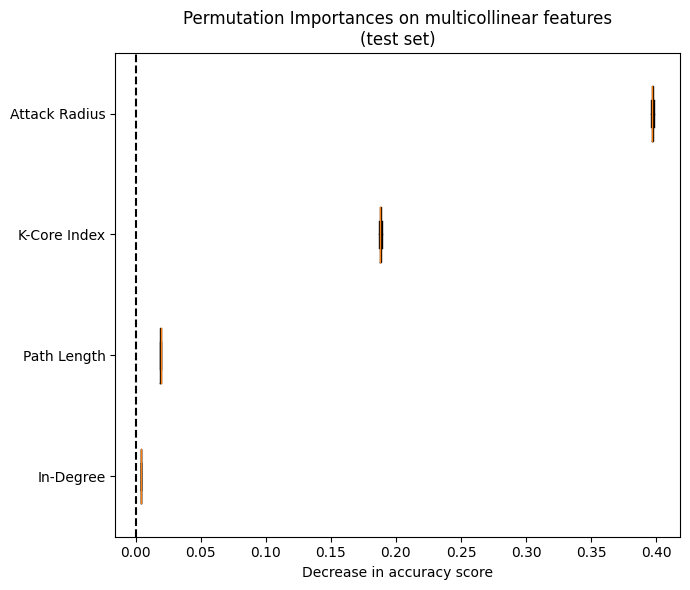

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.inspection import permutation_importance


def plot_permutation_importance(clf, X, y, ax):
    result = permutation_importance(clf, X, y, n_repeats=10, random_state=42, n_jobs=2)
    perm_sorted_idx = result.importances_mean.argsort()

    ax.boxplot(
        result.importances[perm_sorted_idx].T,
        vert=False,
        labels=X.columns[perm_sorted_idx],
    )
    ax.axvline(x=0, color="k", linestyle="--")
    return ax

mdi_importances = pd.Series(gb_classifier.feature_importances_, index=X_resampled.columns)
tree_importance_sorted_idx = np.argsort(gb_classifier.feature_importances_)
tree_indices = np.arange(0, len(gb_classifier.feature_importances_)) + 0.5

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 8))
mdi_importances.sort_values().plot.barh(ax=ax1)
ax1.set_xlabel("Gini importance")
plot_permutation_importance(gb_classifier, X_resampled, y_resampled, ax2)
ax2.set_xlabel("Decrease in accuracy score")
fig.suptitle(
    "Impurity-based vs. permutation importances on multicollinear features (train set)"
)
_ = fig.tight_layout()

fig, ax = plt.subplots(figsize=(7, 6))
plot_permutation_importance(gb_classifier, X_resampled, y_resampled, ax)
ax.set_title("Permutation Importances on multicollinear features\n(test set)")
ax.set_xlabel("Decrease in accuracy score")
_ = ax.figure.tight_layout()

In [ ]:
from xgboost import XGBClassifier

# Set hyperparameters (optional)
params = {
  'max_depth': 6,  # Maximum depth of decision trees
  'n_estimators': 100,  # Number of boosting iterations
  'learning_rate': 0.1,  # Learning rate for each boosting step
  'objective': 'binary:logistic',  # Objective function for classification (logistic regression)
  'random_state': 42  # Set random seed for reproducibility
}

# Create the XGBoost classifier object
xgb_classifier = XGBClassifier(**params)

# Perform cross-validated predictions
y_pred = cross_val_predict(xgb_classifier, X_resampled, y_resampled, cv=cv)

# Evaluate the predictions
print("XGBoost Classifier on training data")
print("Accuracy:", accuracy_score(y_resampled, y_pred))
print("Confusion Matrix:\n", confusion_matrix(y_resampled, y_pred))
print("Classification Report:\n", classification_report(y_resampled, y_pred))

xgb_classifier.fit(X_resampled, y_resampled)

feature_importance = xgb_classifier.feature_importances_
# Assuming 'X' is your feature DataFrame
feature_importance_df = pd.DataFrame({'Feature': X_resampled.columns, 'Importance': feature_importance})
print(feature_importance_df)

XGBoost Classifier on training data
Accuracy: 0.9588637332403317
Confusion Matrix:
 [[189678  16770]
 [   215 206233]]
Classification Report:
               precision    recall  f1-score   support

       False       1.00      0.92      0.96    206448
        True       0.92      1.00      0.96    206448

    accuracy                           0.96    412896
   macro avg       0.96      0.96      0.96    412896
weighted avg       0.96      0.96      0.96    412896

         Feature  Importance
0  Attack Radius    0.979299
1      In-Degree    0.004134
2   K-Core Index    0.008425
3    Path Length    0.008142
